## 0) (اختياري) Google Colab: تحميل ملف البيانات من Google Drive

إن كنت تعمل على Colab بنفس طريقة ملفك القديم (`/content/drive/MyDrive/DrDoS_SSDP.zip`)، نفّذ هذه الخلية أولًا. إن لم تكن على Colab، تجاهلها ببساطة.

In [1]:
# تنفَّذ فقط داخل Google Colab — تُهيئ الوصول إلى ملفاتك على Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("تم تركيب Google Drive. استخدم مسارًا مثل: /content/drive/MyDrive/DrDoS_SSDP.zip كقيمة لـ DATA_PATH في الخلية التالية.")
except ImportError:
    print("لست على Google Colab — تجاهل هذه الخلية ومرّ مباشرة إلى إعداد DATA_PATH.")

Mounted at /content/drive
تم تركيب Google Drive. استخدم مسارًا مثل: /content/drive/MyDrive/DrDoS_SSDP.zip كقيمة لـ DATA_PATH في الخلية التالية.


# كشف هجمات DDoS: مقارنة أقوى بين النماذج التقليدية والكمومية/الهجينة

**النماذج الستة:** `SVM` · `KNN` · `CNN`  ⟷  `QSVM` · `QKNN` · `QCNN`

**نسخة مُحسّنة للمقارنة المنهجية**

هذه النسخة تنظّم التجربة بحيث تكون المقارنة أقوى إحصائيًا وأكثر إنصافًا، خصوصًا مع بيانات DDoS شديدة اللاتوازن:

1. نفس العينة المشتركة لكل النماذج، لكن مع **حد أدنى للفئة النادرة** بدل sampling طبقي يحافظ على ندرتها الشديدة.
2. نفس التقسيم `Train / Validation / Final Test`، ونفس التنظيف، ونفس التطبيع، ونفس PCA لكل النماذج الستة.
3. كل خطوات الـ preprocessing المعتمدة على إحصاءات البيانات تُدرَّب على **Train فقط** ثم تُطبَّق على Validation و Final Test.
4. ضبط الـ hyperparameters و EarlyStopping على **Validation فقط**، وبنفس ميزانية الضبط لكل زوج.
5. **Final Test** لا يُستخدم إلا للتقييم النهائي لكل seed.
6. المقاييس الأساسية أصبحت مناسبة للّاتوازن: `Balanced_Accuracy`, `F1_macro`, `F1_BENIGN`, `MCC`, و `ROC_AUC`، مع إبقاء Accuracy و F1 للهجوم للقراءة فقط.
7. لا يُقبل استنتاج قوي إذا كان عدد عينات الفئة النادرة في Validation/Test صغيرًا؛ تفشل الخلية مبكرًا عند تفعيل `STRICT_INFERENCE_CHECKS`.

**طريقة التشغيل:** عدّل `DATA_PATH` في الخلية 1.2 إذا لزم، ثم نفّذ الخلايا بالترتيب. استخدم `QUICK_TEST=True` فقط للتأكد من أن الدفتر يعمل، ولا تستخدم نتائجه في الاستنتاج.


## 1) Imports and configuration

In [2]:
# 1.1  الاستيراد
# إذا لم تكن الحزم مثبّتة، نفّذ السطر التالي مرة واحدة ثم أعد تشغيل الـ kernel:
!pip install -q "pennylane>=0.36" scikit-learn torch pandas numpy matplotlib

import os, sys, time, math, zipfile, warnings, random, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             balanced_accuracy_score, matthews_corrcoef, average_precision_score)

import torch
import torch.nn as nn
import pennylane as qml

try:
    from IPython.display import display
except Exception:          # تشغيل خارج Jupyter
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

print("Python", platform.python_version(), "| NumPy", np.__version__, "| pandas", pd.__version__,
      "| torch", torch.__version__, "| PennyLane", qml.__version__)

Python 3.13.16 | NumPy 2.4.6 | pandas 2.2.3 | torch 2.14.1+cu130 | PennyLane 0.45.1


In [3]:
# 1.2  الإعدادات (كل ما قد تحتاج تعديله موجود هنا)
# ------------------------------------------------------------------------------------------
DATA_PATH  = "/content/drive/MyDrive/DrDoS_SSDP.zip"     # CSV أو CSV.GZ أو ZIP يحتوي CSV أو مجلد يحتوي CSV
OUTPUT_DIR = "ddos_qml_outputs"                         # تُحفظ هنا الجداول والرسوم

# ---- وضع التشغيل ----
FULL_CLASSICAL_RUN   = False   # True: تشغيل إضافي (مرجعي فقط) للنماذج التقليدية على كامل بيانات التدريب المتاحة.
                               #       لا يدخل في المقارنة العادلة، ويُعرض في جدول منفصل.

# في بيانات DDoS شديدة اللاتوازن، sampling طبقي عادي قد يعطي Test فيه عينتان فقط من BENIGN.
# لذلك الافتراضي هنا يأخذ كل الفئة النادرة المتاحة تقريبًا ثم يملأ بقية العينة من الفئة الأكبر.
FAIR_QML_SAMPLE_SIZE = 12_000
FAIR_SAMPLE_STRATEGY = "min_class_floor"   # "min_class_floor" موصى بها للاستنتاج؛ "stratified" فقط لمطابقة التوزيع الأصلي حرفيًا.
MIN_CLASS_FLOOR      = 1_500               # إن كانت الفئة النادرة أقل من هذا العدد، تُستخدم كلها تقريبًا دون oversampling.
MIN_TRAIN_MINORITY   = 100                 # حد أدنى لقبول تدريب له معنى على الفئة النادرة.
MIN_EVAL_MINORITY    = 100                 # حد أدنى في Validation و Final Test لقبول استنتاج قوي.
STRICT_INFERENCE_CHECKS = True             # True: أوقف التشغيل إذا كان Validation/Test غير كافيين للفئة النادرة.

SEEDS = [42, 43, 44, 45, 46]               # زِدها إلى 10+ عند إعداد تقرير نهائي أو ورقة.
MIN_SEEDS_FOR_STRONG_CLAIM = 5
QUICK_TEST = False                         # True: إعدادات مصغّرة للتأكد من التشغيل فقط، لا تستخدم نتائجها للاستنتاج.

# ---- القراءة والتنظيف ----
MAX_ROWS_TO_READ = None         # للتجارب السريعة فقط (مثلاً 200_000). None = قراءة كل السجلات.
CHUNK_ROWS       = 250_000
BENIGN_LABELS    = {"BENIGN"}  # أي تسمية غير موجودة هنا تُعتبر هجومًا (1). التسميات تُقارَن بعد strip و upper.
DROP_DUPLICATES  = True         # حذف الصفوف المكررة (ميزات+label) قبل التقسيم لمنع ظهور نفس الصف في Train و Test.

# ---- التقسيم (نسب من العينة المشتركة) ----
TEST_FRACTION = 0.20
VAL_FRACTION  = 0.20            # الباقي (60%) Train

# ---- المعالجة المشتركة ----
N_FEATURES_GRID = [2, 4, 6]     # عدد مكوّنات PCA المُجرَّبة (= عدد الكيوبتات للنماذج الكمومية)
ANGLE_SCALE     = np.pi / 2     # RX(ANGLE_SCALE * x), x ∈ [-1, 1]. pi/2 يتجنب تطابق x=-1 و x=+1 بطور عام فقط.

# ---- ميزانية الضبط (متساوية لكل زوج؛ تُفحص تلقائيًا في الخلية التالية) ----
C_GRID          = [0.1, 1.0, 10.0, 100.0]        # SVM و QSVM
GAMMA_GRID      = [0.25, 1.0, 4.0]               # SVM (شكل النواة)      ↔ عمق الـ feature map لـ QSVM
FM_DEPTH_GRID   = [1, 2, 3]                      # QSVM و QKNN (شكل النواة الكمومية)
KNN_METRICS     = ["euclidean", "manhattan", "chebyshev"]  # KNN (شكل المسافة) ↔ عمق الـ feature map لـ QKNN
K_GRID          = [1, 3, 5, 7, 11]               # k مشترك بين KNN و QKNN (يُختار مرة واحدة للاثنين)
CNN_FILTERS_GRID = [2, 4]                        # CNN (حجم الشبكة)      ↔ عدد طبقات الالتفاف لـ QCNN
QCNN_REPS_GRID   = [1, 2]
LR_GRID          = [0.05, 0.01]                  # نفس معدلات التعلم لـ CNN و QCNN
MAX_EPOCHS, PATIENCE, BATCH_SIZE = 20, 4, 128    # نفس الميزانية لـ CNN و QCNN (EarlyStopping على Validation فقط)

# ---- الجولة التقليدية الكاملة (تُستخدم فقط إذا FULL_CLASSICAL_RUN=True) ----
FULL_SVM_MAX_TRAIN = 50_000     # SVC-RBF لا يتحمل ملايين الصفوف؛ نقصّ التدريب إلى هذا الحد (stratified)
FULL_BATCH_SIZE    = 1024

MAX_KERNEL_GB = 6.0             # حد أمان لذاكرة مصفوفات الـ kernel


In [4]:
# 1.3  تطبيق QUICK_TEST + فحص تساوي ميزانية الضبط + أدوات عامة
if QUICK_TEST:
    FAIR_QML_SAMPLE_SIZE = 2_000
    MIN_CLASS_FLOOR = 100
    MIN_TRAIN_MINORITY, MIN_EVAL_MINORITY = 5, 5
    STRICT_INFERENCE_CHECKS = False
    SEEDS            = SEEDS[:2]
    N_FEATURES_GRID  = [2, 4]
    C_GRID, GAMMA_GRID, FM_DEPTH_GRID = [1.0, 10.0], [0.25, 1.0], [1, 2]
    KNN_METRICS, K_GRID = ["euclidean", "manhattan"], [3, 5]
    CNN_FILTERS_GRID, QCNN_REPS_GRID, LR_GRID = [2, 4], [1, 2], [0.05]
    MAX_EPOCHS, PATIENCE = 3, 2
    FULL_SVM_MAX_TRAIN = 3_000
    print("⚠️  QUICK_TEST=True : إعدادات مصغّرة، لا تستخدم نتائجها في أي استنتاج.")

if len(SEEDS) < MIN_SEEDS_FOR_STRONG_CLAIM:
    print(f"⚠️ عدد الـ seeds = {len(SEEDS)} أقل من الحد المقترح ({MIN_SEEDS_FOR_STRONG_CLAIM}) للاستنتاج القوي.")

MAX_F = max(N_FEATURES_GRID)                      # عدد مكوّنات PCA التي تُدرَّب مرة واحدة (الأصغر = أول k عمود منها)
MODEL_ORDER = ["SVM", "QSVM", "KNN", "QKNN", "CNN", "QCNN"]
PAIRS = [("SVM", "QSVM"), ("KNN", "QKNN"), ("CNN", "QCNN")]

def check_equal_tuning_budget():
    """يتأكد أن عدد التهيئات المجرَّبة (لكل قيمة n_features) متساوٍ داخل كل زوج تقليدي/كمومي."""
    budget = {
        "SVM  / QSVM":  (len(C_GRID) * len(GAMMA_GRID),            len(C_GRID) * len(FM_DEPTH_GRID)),
        "KNN  / QKNN":  (len(KNN_METRICS) * len(K_GRID),           len(FM_DEPTH_GRID) * len(K_GRID)),
        "CNN  / QCNN":  (len(CNN_FILTERS_GRID) * len(LR_GRID),     len(QCNN_REPS_GRID) * len(LR_GRID)),
    }
    for pair, (a, b) in budget.items():
        print(f"ميزانية الضبط {pair}: {a} تهيئة مقابل {b} تهيئة (لكل قيمة n_features) × {len(N_FEATURES_GRID)} قيم n_features")
        assert a == b, f"ميزانية الضبط غير متساوية في الزوج {pair}: عدّل الـ grids."
check_equal_tuning_budget()

def set_global_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

ميزانية الضبط SVM  / QSVM: 12 تهيئة مقابل 12 تهيئة (لكل قيمة n_features) × 3 قيم n_features
ميزانية الضبط KNN  / QKNN: 15 تهيئة مقابل 15 تهيئة (لكل قيمة n_features) × 3 قيم n_features
ميزانية الضبط CNN  / QCNN: 4 تهيئة مقابل 4 تهيئة (لكل قيمة n_features) × 3 قيم n_features


## 2) Data loading

- يقرأ CSV أو CSV.GZ أو ZIP (كل ملفات CSV بداخله) أو مجلدًا، **على دفعات** (chunks) مع تحويل الأعمدة إلى `float32` لتوفير الذاكرة (مليونا سجل × ~87 ميزة).
- تُنظَّف أسماء الأعمدة من المسافات الزائدة، ويُكتشف عمود التصنيف بغضّ النظر عن حالة الأحرف والمسافات (`" Label"` / `"Label"` / `"label"`) ثم يُوحَّد اسمه إلى `Label`.
- الأعمدة غير المفيدة (Flow ID, IPs, Timestamp, Ports ...) تُستبعد **أثناء القراءة** لتوفير الذاكرة؛ والتقرير في القسم 3.

In [5]:
# 2.1  دوال القراءة
META_COLUMNS = {"flow id", "source ip", "src ip", "destination ip", "dst ip", "timestamp",
                "source port", "src port", "destination port", "dst port", "simillarhttp", "similarhttp"}

def is_meta_column(col) -> bool:
    """أعمدة هوية/شبكة لا تفيد التعميم (وتسبّب تسريبًا غير مشروع للمعلومات)، تُقارَن بعد strip و lower."""
    c = str(col).strip().lower()
    return c in META_COLUMNS or c.startswith("unnamed")

def find_label_column(columns):
    """يجد عمود التصنيف مهما كانت المسافات أو حالة الأحرف: ' Label' / 'Label' / 'label'."""
    for c in columns:
        if str(c).strip().lower() == "label":
            return c
    raise KeyError(f"لم أجد عمود Label. الأعمدة الموجودة (أول 15): {list(columns)[:15]}")

def iter_csv_sources(path):
    """يُنتج (اسم, مصدر) لكل ملف CSV: ملف مفرد، أو كل CSV داخل ZIP، أو كل CSV داخل مجلد."""
    p = Path(path)
    if not p.exists():
        raise FileNotFoundError(f"المسار غير موجود: {path}")
    if p.is_dir():
        files = sorted(list(p.glob("*.csv")) + list(p.glob("*.csv.gz")))
        if not files:
            raise ValueError(f"لا توجد ملفات CSV داخل المجلد {path}")
        for f in files:
            yield f.name, str(f)
    elif p.suffix.lower() == ".zip":
        with zipfile.ZipFile(p) as zf:
            names = sorted(n for n in zf.namelist() if n.lower().endswith(".csv") and not n.startswith("__MACOSX"))
            if not names:
                raise ValueError("لا يوجد ملف CSV داخل ملف ZIP")
            for n in names:
                with zf.open(n) as fh:
                    yield n, fh
    else:
        yield p.name, str(p)

def load_raw_dataset(path, chunk_rows=250_000, max_rows=None):
    """يقرأ البيانات على دفعات. يُعيد DataFrame: أعمدة الميزات float32 + عمود 'Label' نصي."""
    dropped_at_read, parts, n_read = set(), [], 0

    def usecols_fn(col):                       # تُستدعى أثناء الـ parsing لتجاهل الأعمدة غير المفيدة
        if is_meta_column(col):
            dropped_at_read.add(str(col).strip())
            return False
        return True

    for src_name, src in iter_csv_sources(path):
        print(f"  قراءة: {src_name}")
        reader = pd.read_csv(src, chunksize=chunk_rows, usecols=usecols_fn, low_memory=False, encoding_errors="replace")
        for chunk in reader:
            chunk.columns = [str(c).strip() for c in chunk.columns]          # ← إزالة المسافات الزائدة من الأسماء
            label_col = find_label_column(chunk.columns)
            labels = chunk[label_col].astype(str).str.strip()
            feats = chunk.drop(columns=[label_col]).apply(pd.to_numeric, errors="coerce")   # كل شيء إلى numeric
            with np.errstate(over="ignore"):
                feats = feats.astype(np.float32)
            feats["Label"] = labels.to_numpy(dtype=object)
            parts.append(feats)
            n_read += len(feats)
            if max_rows and n_read >= max_rows:
                break
        if max_rows and n_read >= max_rows:
            break
    df = pd.concat(parts, ignore_index=True)
    if max_rows:
        df = df.iloc[:max_rows].reset_index(drop=True)
    return df, sorted(dropped_at_read)

In [6]:
# 2.3  تنفيذ القراءة
if str(DATA_PATH).startswith("ضع_هنا"):
    raise ValueError("عدّل DATA_PATH في الخلية 1.2 ليشير إلى ملف البيانات (CSV أو CSV.GZ أو ZIP أو مجلد).")

t0 = time.perf_counter()
df_raw, dropped_at_read = load_raw_dataset(DATA_PATH, CHUNK_ROWS, MAX_ROWS_TO_READ)
print(f"تمت القراءة في {time.perf_counter() - t0:.1f}s | الشكل = {df_raw.shape} | الذاكرة ≈ {df_raw.memory_usage(deep=True).sum() / 1e9:.2f} GB")
print("أعمدة غير مفيدة استُبعدت أثناء القراءة:", dropped_at_read)
print("أول 8 أسماء أعمدة بعد التنظيف:", list(df_raw.columns[:8]))
display(df_raw["Label"].value_counts().to_frame("count"))


  قراءة: DrDoS_SSDP.csv
تمت القراءة في 47.7s | الشكل = (2611374, 80) | الذاكرة ≈ 0.98 GB
أعمدة غير مفيدة استُبعدت أثناء القراءة: ['Destination IP', 'Destination Port', 'Flow ID', 'SimillarHTTP', 'Source IP', 'Source Port', 'Timestamp', 'Unnamed: 0']
أول 8 أسماء أعمدة بعد التنظيف: ['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min']


,count
Label,
DrDoS_SSDP,2610611
BENIGN,763


## 3) Cleaning

خطوات **غير معتمدة على إحصاءات البيانات** (لذلك لا تسبب data leakage، وتُنفَّذ قبل التقسيم):
تنظيف أسماء الأعمدة، حذف الأعمدة غير المفيدة، تحويل `±inf` إلى `NaN`، تحويل التصنيف إلى ثنائي (BENIGN=0 / هجوم=1)، وحذف الصفوف المكررة.

أما الخطوات **المعتمدة على إحصاءات** (حذف الأعمدة ذات القيمة الواحدة، imputation، scaling، PCA) فتُنفَّذ في القسم 6 على **Train فقط**.
حتى «العمود ذو القيمة الواحدة» نكتشفه من Train فقط لأن اكتشافه من كل البيانات يستخدم معلومة من Test.

In [7]:
# 3.1  التنظيف
def clean_dataset(df, benign_labels, drop_duplicates):
    df.columns = [str(c).strip() for c in df.columns]
    meta_left = [c for c in df.columns if is_meta_column(c)]
    if meta_left:
        df = df.drop(columns=meta_left)
    label_col = find_label_column(df.columns)
    if label_col != "Label":
        df = df.rename(columns={label_col: "Label"})

    n0 = len(df)
    bad = df["Label"].isna() | (df["Label"].astype(str).str.strip().str.lower().isin(["", "nan"]))
    df = df.loc[~bad]
    n_bad_label = int(bad.sum())

    n_dup = 0
    if drop_duplicates:
        dup = df.duplicated(keep="first").to_numpy()      # الصف المكرر = نفس الميزات ونفس الـ Label
        n_dup = int(dup.sum())
        df = df.loc[~dup]

    attack_names = df["Label"].astype(str).str.strip().to_numpy(dtype=object)           # اسم الفئة الأصلي (للـ stratification والتقارير)
    benign_upper = {b.strip().upper() for b in benign_labels}
    y = (~pd.Series(attack_names).str.upper().isin(benign_upper)).astype(np.int8).to_numpy()   # 0=BENIGN, 1=هجوم

    feature_names = [c for c in df.columns if c != "Label"]
    X = df[feature_names].to_numpy(dtype=np.float32, copy=True)   # copy=True: بعض إصدارات pandas (Copy-on-Write) تُعيد مصفوفة للقراءة فقط بدونه
    del df
    n_inf = int(np.isinf(X).sum())
    n_nan_before = int(np.isnan(X).sum())
    X[~np.isfinite(X)] = np.nan            # inf/-inf → NaN (تحويل عنصري بحت، لا يعتمد على أي إحصاء). SimpleImputer يعالج NaN في القسم 6
    report = dict(rows_before=n0, rows_bad_label=n_bad_label, rows_duplicates=n_dup, rows_after=len(y),
                  n_features=len(feature_names), n_inf_replaced=n_inf, n_nan_original=n_nan_before)
    return X, y, attack_names, feature_names, report

X_all, y_all, attack_all, feature_names, clean_report = clean_dataset(df_raw, BENIGN_LABELS, DROP_DUPLICATES)
del df_raw
DATA = {"X": X_all, "y": y_all, "attack": attack_all, "features": feature_names}

print("تقرير التنظيف:", clean_report)
print(f"الشكل النهائي: X={X_all.shape}, الذاكرة ≈ {X_all.nbytes / 1e9:.2f} GB")
print("توزيع الفئات الأصلية:"); display(pd.Series(attack_all).value_counts().to_frame("count"))
print(f"توزيع التصنيف الثنائي: BENIGN(0)={int((y_all == 0).sum()):,} | ATTACK(1)={int((y_all == 1).sum()):,}")
if len(np.unique(y_all)) < 2:
    raise ValueError("البيانات تحتوي فئة واحدة فقط بعد التحويل الثنائي؛ تحقق من BENIGN_LABELS.")

تقرير التنظيف: {'rows_before': 2611374, 'rows_bad_label': 0, 'rows_duplicates': 1721145, 'rows_after': 890229, 'n_features': 79, 'n_inf_replaced': 1538, 'n_nan_original': 2}
الشكل النهائي: X=(890229, 79), الذاكرة ≈ 0.28 GB
توزيع الفئات الأصلية:


,count
DrDoS_SSDP,889489
BENIGN,740


توزيع التصنيف الثنائي: BENIGN(0)=740 | ATTACK(1)=889,489


## 4) Fair sampling

كل النماذج الستة تُدرَّب وتُقيَّم على **نفس العينة المشتركة** `FAIR_QML_SAMPLE_SIZE`.

في بيانات DDoS غالبًا تكون `BENIGN` نادرة جدًا. لو استخدمنا stratified sampling يحافظ على التوزيع الأصلي، قد ينتهي Final Test بعينة أو عينتين فقط من BENIGN، وعندها تصبح Accuracy و ROC-AUC و macro-F1 غير مستقرة.

لذلك الافتراضي في هذه النسخة هو `FAIR_SAMPLE_STRATEGY="min_class_floor"`:
- يأخذ عددًا كافيًا من الفئة النادرة، أو يأخذها كلها إذا كانت أقل من `MIN_CLASS_FLOOR`.
- يملأ بقية العينة من الفئة الأكبر.
- لا يستخدم oversampling؛ كل الصفوف حقيقية من البيانات.

هذا يجعل الاستنتاج أقوى، مع بقاء الإنصاف محفوظًا لأن كل النماذج ترى نفس العينة ونفس التقسيم.


In [8]:
# 4.1  العينة المشتركة الأقوى للاستنتاج (نفسها لكل النماذج)
def pick_strat_labels(attack_subset, y_subset, min_count):
    """تقسيم طبقي حسب اسم الفئة الأصلية إن كانت كل فئة فيها ≥ min_count، وإلا حسب التصنيف الثنائي."""
    vc = pd.Series(attack_subset).value_counts()
    if len(vc) > 2 and vc.min() >= min_count:
        return np.asarray(attack_subset)
    return np.asarray(y_subset)

def _balanced_binary_targets(y, size, floor):
    """أهداف عينة بلا oversampling: نرفع حضور الفئة النادرة ثم نحافظ على الحجم الكلي."""
    classes, counts = np.unique(y, return_counts=True)
    if len(classes) != 2:
        raise ValueError("هذه التجربة ثنائية التصنيف؛ تحقق من BENIGN_LABELS وتحويل y.")
    N = len(y)
    target = {}
    for c, cnt in zip(classes, counts):
        proportional = int(round(size * cnt / N))
        target[int(c)] = int(min(cnt, max(proportional, min(floor, int(cnt)))))

    # إذا تجاوز مجموع الحدود الدنيا حجم العينة، نقلل من الفئة الأكبر أولًا دون النزول تحت 1.
    while sum(target.values()) > size:
        c = max(target, key=lambda k: target[k])
        if target[c] <= 1:
            raise ValueError("FAIR_QML_SAMPLE_SIZE صغير جدًا مقارنة بعدد الفئات والحدود الدنيا.")
        target[c] -= 1

    # إذا بقيت مساحة، نضيفها للفئة التي تملك صفوفًا غير مستخدمة، مع تفضيل الأكبر.
    counts_by_class = {int(c): int(cnt) for c, cnt in zip(classes, counts)}
    while sum(target.values()) < size:
        candidates = [c for c in target if target[c] < counts_by_class[c]]
        if not candidates:
            break
        c = max(candidates, key=lambda k: counts_by_class[k] - target[k])
        target[c] += 1
    return target

def make_fair_sample(y, attack, size, strategy, floor, seed):
    """يُعيد فهارس (مرتّبة) العينة المشتركة من كامل البيانات النظيفة."""
    N = len(y)
    if size is None or size >= N:
        return np.arange(N)
    if strategy == "stratified":
        strat = pick_strat_labels(attack, y, min_count=50)
        idx, _ = train_test_split(np.arange(N), train_size=int(size), stratify=strat, random_state=seed)
        return np.sort(idx)
    if strategy == "min_class_floor":
        rng = np.random.default_rng(seed)
        target = _balanced_binary_targets(y, int(size), int(floor))
        parts = [rng.choice(np.where(y == c)[0], size=t, replace=False) for c, t in target.items()]
        return np.sort(np.concatenate(parts))
    raise ValueError("FAIR_SAMPLE_STRATEGY غير معروف")

def new_state(seed):
    """كل seed له حالة مستقلة: عينة، تقسيم، preprocessing، نماذج، نتائج."""
    return {"seed": seed, "logs": {}, "models": {}, "full_models": {}}

def step4_fair_sampling(state, verbose=True):
    y, attack = DATA["y"], DATA["attack"]
    idx_sample = make_fair_sample(y, attack, FAIR_QML_SAMPLE_SIZE, FAIR_SAMPLE_STRATEGY, MIN_CLASS_FLOOR, state["seed"])
    state["idx_sample"] = idx_sample
    if verbose:
        n_b, n_a = int((y[idx_sample] == 0).sum()), int((y[idx_sample] == 1).sum())
        print(f"[seed={state['seed']}] العينة المشتركة: {len(idx_sample):,} من أصل {len(y):,} سجل "
              f"| BENIGN={n_b:,} | ATTACK={n_a:,} | الاستراتيجية={FAIR_SAMPLE_STRATEGY}")
        print(f"  نسبة الهجوم في كامل البيانات = {y.mean():.4%} ، في العينة = {y[idx_sample].mean():.4%}")
        if min(n_b, n_a) < (MIN_TRAIN_MINORITY + 2 * MIN_EVAL_MINORITY):
            print("  ⚠️ الفئة الأقل تكرارًا قد لا تكفي لتقسيم قوي. زد FAIR_QML_SAMPLE_SIZE أو خفف حدود MIN_* إن كنت في QUICK_TEST.")
    return state

STATE = new_state(SEEDS[0])           # الـ seed الأساسي يُنفَّذ خطوة بخطوة في الأقسام 4–9
set_global_seed(STATE["seed"])
step4_fair_sampling(STATE);


[seed=42] العينة المشتركة: 12,000 من أصل 890,229 سجل | BENIGN=740 | ATTACK=11,260 | الاستراتيجية=min_class_floor
  نسبة الهجوم في كامل البيانات = 99.9169% ، في العينة = 93.8333%


## 5) Train / Validation / Final-Test split

تقسيم طبقي (stratified) بـ seed ثابت **داخل العينة المشتركة**: Train 60% / Validation 20% / Final Test 20%.

- **Train**: تدريب النماذج وتدريب كل خطوات الـ preprocessing.
- **Validation**: ضبط الـ hyperparameters و EarlyStopping واختيار n_features/العمق/k.
- **Final Test**: التقييم النهائي فقط (القسم 9).
- الصفوف خارج العينة (`extra`) لا تدخل أبدًا في Validation أو Test؛ تُستخدم فقط في الجولة المرجعية `FULL_CLASSICAL_RUN` كبيانات تدريب إضافية.

In [9]:
# 5.1  التقسيم + فحص قوة العينة
def make_split(idx_sample, y, attack, seed):
    N = len(y)
    try:
        strat = pick_strat_labels(attack[idx_sample], y[idx_sample], min_count=10)
        idx_trval, idx_test = train_test_split(idx_sample, test_size=TEST_FRACTION, stratify=strat, random_state=seed)
        strat_tv = pick_strat_labels(attack[idx_trval], y[idx_trval], min_count=10)
        idx_train, idx_val = train_test_split(idx_trval, test_size=VAL_FRACTION / (1 - TEST_FRACTION),
                                              stratify=strat_tv, random_state=seed)
    except ValueError as e:
        raise ValueError("تعذّر التقسيم الطبقي لأن إحدى الفئات نادرة جدًا في العينة المشتركة. "
                         "استخدم FAIR_SAMPLE_STRATEGY='min_class_floor' أو زد FAIR_QML_SAMPLE_SIZE. التفاصيل: " + str(e))
    idx_extra = np.setdiff1d(np.arange(N), idx_sample, assume_unique=True)
    split = {"train": np.sort(idx_train), "val": np.sort(idx_val), "test": np.sort(idx_test), "extra": idx_extra}
    assert not (set(split["train"]) & set(split["val"])) and not (set(split["train"]) & set(split["test"])) \
        and not (set(split["val"]) & set(split["test"])), "تداخل بين Train/Val/Test!"
    assert not (set(split["extra"]) & (set(split["val"]) | set(split["test"]))), "extra يتداخل مع Val/Test!"
    return split

def split_strength_table(split, y):
    rows = []
    for name in ["train", "val", "test"]:
        ii = split[name]
        benign = int((y[ii] == 0).sum())
        attack = int((y[ii] == 1).sum())
        rows.append({"المجموعة": {"train": "Train", "val": "Validation", "test": "Final Test"}[name],
                     "الحجم": len(ii), "BENIGN": benign, "ATTACK": attack,
                     "الفئة الأقل": min(benign, attack), "نسبة الهجوم": f"{y[ii].mean():.4%}"})
    return pd.DataFrame(rows)

def validate_split_strength(tbl):
    train_min = int(tbl.loc[tbl["المجموعة"] == "Train", "الفئة الأقل"].iloc[0])
    val_min = int(tbl.loc[tbl["المجموعة"] == "Validation", "الفئة الأقل"].iloc[0])
    test_min = int(tbl.loc[tbl["المجموعة"] == "Final Test", "الفئة الأقل"].iloc[0])
    problems = []
    if train_min < MIN_TRAIN_MINORITY:
        problems.append(f"Train يحتوي {train_min} فقط من الفئة النادرة (< {MIN_TRAIN_MINORITY}).")
    if val_min < MIN_EVAL_MINORITY:
        problems.append(f"Validation يحتوي {val_min} فقط من الفئة النادرة (< {MIN_EVAL_MINORITY}).")
    if test_min < MIN_EVAL_MINORITY:
        problems.append(f"Final Test يحتوي {test_min} فقط من الفئة النادرة (< {MIN_EVAL_MINORITY}).")
    if problems:
        msg = "لا يمكن بناء استنتاج قوي بهذه العينة:\n- " + "\n- ".join(problems) + \
              "\nالحل: استخدم FAIR_SAMPLE_STRATEGY='min_class_floor'، أو زد FAIR_QML_SAMPLE_SIZE، أو خفف الحدود فقط في QUICK_TEST."
        if STRICT_INFERENCE_CHECKS:
            raise ValueError(msg)
        print("⚠️ " + msg)

def step5_split(state, verbose=True):
    y = DATA["y"]
    state["split"] = make_split(state["idx_sample"], y, DATA["attack"], state["seed"])
    tbl = split_strength_table(state["split"], y)
    state["split_strength"] = tbl
    validate_split_strength(tbl)
    if verbose:
        display(tbl)
        print(f"صفوف إضافية خارج العينة (تُستخدم فقط في الجولة المرجعية FULL_CLASSICAL_RUN): {len(state['split']['extra']):,}")
    return state

step5_split(STATE);


,المجموعة,الحجم,BENIGN,ATTACK,الفئة الأقل,نسبة الهجوم
0,Train,7200,444,6756,444,93.8333%
1,Validation,2400,148,2252,148,93.8333%
2,Final Test,2400,148,2252,148,93.8333%


صفوف إضافية خارج العينة (تُستخدم فقط في الجولة المرجعية FULL_CLASSICAL_RUN): 878,229


## 6) Shared preprocessing fitted on Train only

سلسلة واحدة تُدرَّب على **Train فقط** ثم تُطبَّق كما هي على Validation و Final Test (وعلى كل النماذج الستة):

`حذف الأعمدة الثابتة (Train) → SimpleImputer(median) → StandardScaler → PCA → MinMaxScaler[-1,1] → clip[-1,1]`

نُدرّب PCA مرة واحدة بـ `max(N_FEATURES_GRID)` مكوّنًا؛ ومكوّنات PCA مرتّبة ومتداخلة، فالنسخة ذات k مكوّنًا = أول k عمود (والـ MinMax يعمل عمودًا عمودًا فهو متداخل أيضًا).
هذا يعطي النماذج التقليدية والكمومية **نفس المدخلات تمامًا** لكل قيمة n_features.

In [10]:
# 6.1  فئة المعالجة المشتركة (fit على Train فقط)
class SharedPreprocessor:
    def __init__(self, n_components, seed):
        self.n_components, self.seed = n_components, seed

    def fit(self, X_train):
        X_train = np.asarray(X_train, dtype=np.float64)
        self.n_fit_rows_ = len(X_train)                       # لنتحقق لاحقًا أن الـ fit تم على Train فقط
        n_unique = pd.DataFrame(X_train).nunique(dropna=True).to_numpy()
        self.keep_ = n_unique > 1                             # حذف الأعمدة ذات القيمة الواحدة (أو الفارغة) — محسوب من Train فقط
        Xk = X_train[:, self.keep_]
        self.imputer_ = SimpleImputer(strategy="median").fit(Xk)           # NaN (ومنها inf الأصلية) → median من Train
        Xi = self.imputer_.transform(Xk)
        self.scaler_ = StandardScaler().fit(Xi)
        Xs = self.scaler_.transform(Xi)
        n_comp = min(self.n_components, Xs.shape[1])
        self.pca_ = PCA(n_components=n_comp, svd_solver="full", random_state=self.seed).fit(Xs)
        Xp = self.pca_.transform(Xs)
        self.minmax_ = MinMaxScaler(feature_range=(-1, 1)).fit(Xp)         # للمجال [-1,1] قبل الترميز الزاوي
        return self

    def transform_unclipped(self, X):
        Xk = np.asarray(X, dtype=np.float64)[:, self.keep_]
        Xp = self.pca_.transform(self.scaler_.transform(self.imputer_.transform(Xk)))
        return self.minmax_.transform(Xp)

    def transform(self, X):
        Z = self.transform_unclipped(X)
        return np.clip(Z, -1.0, 1.0).astype(np.float32)       # clipping إلى [-1,1] قبل Angle Encoding (قيم Val/Test قد تخرج من مجال Train)

    def transform_rows(self, X, idx, chunk=200_000):
        """تطبيق المعالجة على X[idx] على دفعات (مفيد للجولة المرجعية الكبيرة) دون نسخ كل شيء دفعة واحدة."""
        return np.vstack([self.transform(X[idx[i:i + chunk]]) for i in range(0, len(idx), chunk)])

class FinalTestHolder:
    """يحمل Final Test بعد تطبيق المعالجة عليه. يجب استدعاء get() مرة واحدة فقط (في القسم 9)."""
    def __init__(self, Z, y):
        self._Z, self._y, self.n_access = Z, y, 0
    def __len__(self):
        return len(self._y)
    def get(self):
        self.n_access += 1
        if self.n_access > 1:
            print(f"⚠️ تحذير: تم الوصول إلى Final Test {self.n_access} مرات. المنهجية تسمح باستخدامه مرة واحدة فقط لكل seed.")
        return self._Z, self._y

def step6_preprocess(state, verbose=True):
    X, y, sp = DATA["X"], DATA["y"], state["split"]
    prep = SharedPreprocessor(MAX_F, state["seed"]).fit(X[sp["train"]])              # ← fit على Train فقط (منع data leakage)
    assert prep.n_fit_rows_ == len(sp["train"])
    state["prep"] = prep
    state["Z_train"], state["y_train"] = prep.transform(X[sp["train"]]), y[sp["train"]]
    state["Z_val"],   state["y_val"]   = prep.transform(X[sp["val"]]),   y[sp["val"]]       # transform فقط (بدون fit)
    state["final_test"] = FinalTestHolder(prep.transform(X[sp["test"]]), y[sp["test"]])      # transform فقط؛ يُفتح في القسم 9
    if verbose:
        evr = np.cumsum(prep.pca_.explained_variance_ratio_)
        print(f"[seed={state['seed']}] الميزات الأصلية: {X.shape[1]} → بعد حذف الثابتة (Train): {int(prep.keep_.sum())} → بعد PCA: {prep.pca_.n_components_}")
        print("  التباين المُفسَّر التراكمي: " + " | ".join(f"أول {k}: {evr[k - 1]:.3%}" for k in N_FEATURES_GRID if k <= len(evr)))
        print(f"  Imputer/Scaler/PCA/MinMax دُرِّبت على {prep.n_fit_rows_:,} صف Train فقط.")
        clip_val = float(np.mean(np.abs(prep.transform_unclipped(X[sp["val"]])) > 1.0))
        print(f"  مدى Train بعد MinMax+clip: [{state['Z_train'].min():.2f}, {state['Z_train'].max():.2f}] | "
              f"نسبة قيم Validation التي احتاجت clipping: {clip_val:.4%}")
        print("  عدد الميزات (= عدد الكيوبتات للنماذج الكمومية) المُجرَّب:", N_FEATURES_GRID)
    return state

step6_preprocess(STATE);

[seed=42] الميزات الأصلية: 79 → بعد حذف الثابتة (Train): 67 → بعد PCA: 6
  التباين المُفسَّر التراكمي: أول 2: 35.168% | أول 4: 54.159% | أول 6: 65.142%
  Imputer/Scaler/PCA/MinMax دُرِّبت على 7,200 صف Train فقط.
  مدى Train بعد MinMax+clip: [-1.00, 1.00] | نسبة قيم Validation التي احتاجت clipping: 0.0417%
  عدد الميزات (= عدد الكيوبتات للنماذج الكمومية) المُجرَّب: [2, 4, 6]


## 7) Classical models

| الزوج | ما يُضبط على Validation (لكل قيمة n_features ∈ `N_FEATURES_GRID`) | عدد التهيئات |
|---|---|---|
| **SVM** ↔ QSVM | `C` × `gamma` (RBF) ↔ `C` × عمق الـ feature map | متساوٍ |
| **KNN** ↔ QKNN | المسافة (euclidean/manhattan/chebyshev) × `k` ↔ عمق الـ feature map × `k` | متساوٍ |
| **CNN** ↔ QCNN | عدد المرشّحات × lr ↔ عدد طبقات الالتفاف × lr | متساوٍ |

- معيار الاختيار في كل مكان: **macro-F1 على Validation** (متين تجاه اللاتوازن)؛ وعند التعادل تُختار أول تهيئة في ترتيب الـ grid (الأبسط).
- `KNN` يستخدم **نفس k** الذي يستخدمه `QKNN`: يُختار k مرة واحدة لكليهما (القسم 8.4) بمتوسط أفضل macro-F1 للنموذجين على Validation، حتى لا نحابي أحدهما.
- `CNN`: Conv1D صغيرة جدًا (طبقتا Conv1D بمرشّحات 2 أو 4 + طبقة Dense) بعدد معاملات من نفس رتبة QCNN؛ تُطبع أعداد المعاملات في النتائج.
- EarlyStopping على **Validation loss فقط**، ثم نستعيد أفضل أوزان.

In [11]:
# 7.1  أدوات مشتركة: النموذج المُدرَّب، المقاييس، تدريب PyTorch (يُستخدم نفسه لـ CNN و QCNN)
class FittedModel:
    """نموذج مُدرَّب. predict_fn(Z) تُعيد (labels, scores) حيث Z مصفوفة PCA بعرض MAX_F (يأخذ النموذج أول n_features عمود)."""
    def __init__(self, name, family, n_features, hyperparams, predict_fn, train_time, tuning_time,
                 n_train, n_params=None, note=""):
        self.name, self.family, self.n_features, self.hyperparams = name, family, int(n_features), hyperparams
        self.predict_fn, self.train_time, self.tuning_time = predict_fn, float(train_time), float(tuning_time)
        self.n_train, self.n_params, self.note = int(n_train), n_params, note

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", zero_division=0)

def best_row(log):
    """أفضل صف حسب val_macro_f1؛ np.argmax يُعيد أول قيمة عند التعادل (= الأبسط حسب ترتيب الـ grid)."""
    return log.iloc[int(np.argmax(log["val_macro_f1"].to_numpy()))]

def count_params(model):
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))

@torch.no_grad()
def torch_predict(model, Z, batch=4096):
    """يُعيد (labels, P(attack)). Softmax يُطبَّق هنا على مخرجات Dense."""
    model.eval()
    probs = [torch.softmax(model(torch.as_tensor(Z[i:i + batch], dtype=torch.float32)), dim=1)[:, 1].numpy()
             for i in range(0, len(Z), batch)]
    p = np.concatenate(probs)
    return (p > 0.5).astype(int), p

@torch.no_grad()
def torch_val_loss(model, Z, y, batch=4096):
    model.eval()
    t = torch.as_tensor(y, dtype=torch.long)
    total = 0.0
    for i in range(0, len(Z), batch):
        logits = model(torch.as_tensor(Z[i:i + batch], dtype=torch.float32))
        total += float(nn.functional.cross_entropy(logits, t[i:i + batch], reduction="sum"))
    return total / len(Z)

def train_torch_classifier(model, Z_tr, y_tr, Z_va, y_va, lr, seed, batch_size, max_epochs, patience):
    """تدريب Adam + CrossEntropy (Softmax). EarlyStopping على Validation loss فقط (لا يُستخدم Final Test إطلاقًا)."""
    gen = torch.Generator().manual_seed(int(seed))
    X_tr = torch.as_tensor(Z_tr, dtype=torch.float32)
    t_tr = torch.as_tensor(y_tr, dtype=torch.long)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best = {"loss": float("inf"), "state": None, "epoch": 0}
    wait, n, epochs_run = 0, len(X_tr), 0
    t0 = time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(n, generator=gen)
        for i in range(0, n, batch_size):
            b = perm[i:i + batch_size]
            if len(b) < 2:
                continue
            opt.zero_grad()
            loss = nn.functional.cross_entropy(model(X_tr[b]), t_tr[b])
            loss.backward()
            opt.step()
        val_loss = torch_val_loss(model, Z_va, y_va)         # ← EarlyStopping: Validation فقط
        epochs_run = epoch
        if val_loss < best["loss"] - 1e-5:
            best = {"loss": val_loss, "state": {k: v.detach().clone() for k, v in model.state_dict().items()}, "epoch": epoch}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best["state"])                      # استعادة أفضل أوزان حسب Validation
    return {"train_time": time.perf_counter() - t0, "val_loss": best["loss"], "best_epoch": best["epoch"], "epochs_run": epochs_run}

def tune_torch_family(state, name, family, build_model, struct_grid, struct_key):
    """نفس البروتوكول حرفيًا لـ CNN و QCNN: نفس lr grid، نفس batch، نفس max_epochs، نفس patience، نفس معيار الاختيار."""
    Z_tr, y_tr, Z_va, y_va = state["Z_train"], state["y_train"], state["Z_val"], state["y_val"]
    rows, best, cfg_id = [], None, 0
    t_start = time.perf_counter()
    for nf in N_FEATURES_GRID:
        for struct in struct_grid:
            for lr in LR_GRID:
                cfg_id += 1
                cfg_seed = state["seed"] * 10_000 + cfg_id
                torch.manual_seed(cfg_seed)                                  # تهيئة أوزان قابلة لإعادة الإنتاج
                model = build_model(nf, struct)
                info = train_torch_classifier(model, Z_tr[:, :nf], y_tr, Z_va[:, :nf], y_va, lr=lr, seed=cfg_seed,
                                              batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS, patience=PATIENCE)
                pred, _ = torch_predict(model, Z_va[:, :nf])
                f1m = macro_f1(y_va, pred)
                rows.append({"model": name, "n_features": nf, struct_key: struct, "lr": lr, "val_macro_f1": f1m,
                             "val_loss": info["val_loss"], "best_epoch": info["best_epoch"], "epochs_run": info["epochs_run"],
                             "train_time_s": info["train_time"], "n_params": count_params(model)})
                if best is None or f1m > best["f1"] + 1e-12 or (abs(f1m - best["f1"]) <= 1e-12 and info["val_loss"] < best["val_loss"]):
                    best = {"model": model, "f1": f1m, "val_loss": info["val_loss"], "nf": nf, "struct": struct, "lr": lr,
                            "train_time": info["train_time"]}
                if state.get("verbose", True):
                    print(f"  {name}: n_features={nf} {struct_key}={struct} lr={lr} → val macro-F1={f1m:.4f} "
                          f"(epochs={info['epochs_run']}, {info['train_time']:.1f}s)")
    tuning_time = time.perf_counter() - t_start
    model, nf = best["model"], best["nf"]
    fm = FittedModel(name, family, nf, {struct_key: best["struct"], "lr": best["lr"]},
                     lambda Z, m=model, k=nf: torch_predict(m, Z[:, :k]),
                     train_time=best["train_time"], tuning_time=tuning_time, n_train=len(y_tr), n_params=count_params(model),
                     note="training time = وقت تدريب أفضل تهيئة (وصلت لـ EarlyStopping)")
    return pd.DataFrame(rows), fm

In [12]:
# 7.2  SVM و KNN و CNN
# ---------------- SVM (RBF) ----------------
def tune_svm(state):
    Z_tr, y_tr, Z_va, y_va = state["Z_train"], state["y_train"], state["Z_val"], state["y_val"]
    rows = []
    for nf in N_FEATURES_GRID:
        for C in C_GRID:
            for gamma in GAMMA_GRID:
                clf = SVC(kernel="rbf", C=C, gamma=gamma, cache_size=1000).fit(Z_tr[:, :nf], y_tr)
                rows.append({"model": "SVM", "n_features": nf, "C": C, "gamma": gamma,
                             "val_macro_f1": macro_f1(y_va, clf.predict(Z_va[:, :nf]))})
    return pd.DataFrame(rows)

def fit_final_svm(state, row, tuning_time, name="SVM", Z_tr=None, y_tr=None):
    nf, C, gamma = int(row["n_features"]), float(row["C"]), float(row["gamma"])
    Z_tr = state["Z_train"] if Z_tr is None else Z_tr
    y_tr = state["y_train"] if y_tr is None else y_tr
    t0 = time.perf_counter()
    clf = SVC(kernel="rbf", C=C, gamma=gamma, cache_size=1000).fit(Z_tr[:, :nf], y_tr)
    train_time = time.perf_counter() - t0
    def predict(Z):
        s = clf.decision_function(Z[:, :nf])
        return (s > 0).astype(int), s
    return FittedModel(name, "classical", nf, {"C": C, "gamma": gamma}, predict, train_time, tuning_time, len(y_tr),
                       note=f"{int(clf.n_support_.sum())} support vectors")

# ---------------- KNN ----------------
def knn_predict_from(knn, X):
    proba = knn.predict_proba(X)[:, list(knn.classes_).index(1)]
    return (proba > 0.5).astype(int), proba            # عند التعادل 0.5 → BENIGN (نفس سلوك sklearn)

def tune_knn(state):
    Z_tr, y_tr, Z_va, y_va = state["Z_train"], state["y_train"], state["Z_val"], state["y_val"]
    rows = []
    for nf in N_FEATURES_GRID:
        for metric in KNN_METRICS:
            for k in K_GRID:
                knn = KNeighborsClassifier(n_neighbors=k, metric=metric).fit(Z_tr[:, :nf], y_tr)
                rows.append({"model": "KNN", "n_features": nf, "metric": metric, "k": k,
                             "val_macro_f1": macro_f1(y_va, knn.predict(Z_va[:, :nf]))})
    return pd.DataFrame(rows)

def fit_final_knn(state, row, k, tuning_time, name="KNN", Z_tr=None, y_tr=None):
    nf, metric = int(row["n_features"]), str(row["metric"])
    Z_tr = state["Z_train"] if Z_tr is None else Z_tr
    y_tr = state["y_train"] if y_tr is None else y_tr
    t0 = time.perf_counter()
    knn = KNeighborsClassifier(n_neighbors=int(k), metric=metric).fit(Z_tr[:, :nf], y_tr)
    train_time = time.perf_counter() - t0
    return FittedModel(name, "classical", nf, {"k": int(k), "metric": metric},
                       lambda Z: knn_predict_from(knn, Z[:, :nf]), train_time, tuning_time, len(y_tr))

# ---------------- CNN (Conv1D صغيرة على ميزات PCA) ----------------
class SmallCNN(nn.Module):
    """Conv1D → ReLU → Conv1D → ReLU → Flatten → Dense(2) [Softmax داخل CrossEntropy]. المدخل: (batch, n_features)."""
    def __init__(self, n_features, n_filters):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(1, n_filters, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv1d(n_filters, n_filters, kernel_size=3, padding=1), nn.ReLU(),
            nn.Flatten(), nn.Linear(n_filters * n_features, 2))
    def forward(self, x):
        return self.net(x.unsqueeze(1))              # (batch, 1, n_features): قناة واحدة، والميزات هي "المحور الزمني"

def tune_cnn(state):
    return tune_torch_family(state, "CNN", "classical", lambda nf, filters: SmallCNN(nf, filters), CNN_FILTERS_GRID, "filters")

# ---------------- تنفيذ القسم 7 ----------------
def show_best(name, log, k=5):
    print(f"\n── أفضل {k} تهيئات لـ {name} حسب Validation macro-F1 ──")
    display(log.sort_values("val_macro_f1", ascending=False, kind="stable").head(k).reset_index(drop=True))

def step7_classical(state, verbose=True):
    state["verbose"] = verbose
    logs, models = state["logs"], state["models"]
    state.setdefault("tune_time", {})
    t0 = time.perf_counter()
    logs["SVM"] = tune_svm(state)
    t_svm = time.perf_counter() - t0
    models["SVM"] = fit_final_svm(state, best_row(logs["SVM"]), t_svm)

    t0 = time.perf_counter()
    logs["KNN"] = tune_knn(state)                          # الاختيار النهائي لـ KNN مؤجَّل إلى 8.4 (k مشترك مع QKNN)
    state["tune_time"]["KNN"] = time.perf_counter() - t0

    logs["CNN"], models["CNN"] = tune_cnn(state)
    if verbose:
        for nm in ["SVM", "KNN", "CNN"]:
            show_best(nm, logs[nm])
        m = models["CNN"]
        print(f"\nCNN المختار: n_features={m.n_features}, {m.hyperparams}, عدد المعاملات = {m.n_params}")
    return state

step7_classical(STATE);

  CNN: n_features=2 filters=2 lr=0.05 → val macro-F1=0.4841 (epochs=17, 2.3s)
  CNN: n_features=2 filters=2 lr=0.01 → val macro-F1=0.4841 (epochs=15, 1.7s)
  CNN: n_features=2 filters=4 lr=0.05 → val macro-F1=0.9964 (epochs=15, 1.7s)
  CNN: n_features=2 filters=4 lr=0.01 → val macro-F1=0.4841 (epochs=11, 1.3s)
  CNN: n_features=4 filters=2 lr=0.05 → val macro-F1=0.9928 (epochs=13, 1.9s)
  CNN: n_features=4 filters=2 lr=0.01 → val macro-F1=0.9891 (epochs=20, 3.1s)
  CNN: n_features=4 filters=4 lr=0.05 → val macro-F1=0.9891 (epochs=20, 2.5s)
  CNN: n_features=4 filters=4 lr=0.01 → val macro-F1=0.9928 (epochs=17, 2.0s)
  CNN: n_features=6 filters=2 lr=0.05 → val macro-F1=0.9964 (epochs=18, 2.1s)
  CNN: n_features=6 filters=2 lr=0.01 → val macro-F1=0.9928 (epochs=20, 2.2s)
  CNN: n_features=6 filters=4 lr=0.05 → val macro-F1=0.9964 (epochs=7, 0.9s)
  CNN: n_features=6 filters=4 lr=0.01 → val macro-F1=0.9928 (epochs=9, 1.2s)

── أفضل 5 تهيئات لـ SVM حسب Validation macro-F1 ──


,model,n_features,C,gamma,val_macro_f1
0,SVM,2,100.0,4.00,0.998205
1,SVM,4,10.0,0.25,0.998205
2,SVM,6,100.0,1.00,0.998205
3,SVM,2,0.1,4.00,0.996422
4,SVM,2,1.0,1.00,0.996422



── أفضل 5 تهيئات لـ KNN حسب Validation macro-F1 ──


,model,n_features,metric,k,val_macro_f1
0,KNN,2,euclidean,1,0.998205
1,KNN,2,manhattan,1,0.998205
2,KNN,2,chebyshev,1,0.998205
3,KNN,4,euclidean,1,0.998205
4,KNN,4,manhattan,1,0.998205



── أفضل 5 تهيئات لـ CNN حسب Validation macro-F1 ──


,model,n_features,filters,lr,val_macro_f1,val_loss,best_epoch,epochs_run,train_time_s,n_params
0,CNN,2,4,0.05,0.996422,0.007578,11,15,1.691127,86
1,CNN,6,2,0.05,0.996422,0.005161,14,18,2.101962,48
2,CNN,6,4,0.05,0.996400,0.005248,3,7,0.854674,118
3,CNN,4,2,0.05,0.992753,0.007230,9,13,1.912640,40
4,CNN,4,4,0.01,0.992753,0.005550,13,17,1.968257,102



CNN المختار: n_features=6, {'filters': 2, 'lr': 0.05}, عدد المعاملات = 48


## 8) Quantum models (PennyLane)

### 8.1 Quantum feature map و fidelity kernel

- **الترميز الزاوي (Angle Encoding):** كل ميزة `x_i ∈ [-1,1]` تُرمَّز كدوران `RX(ANGLE_SCALE · x_i)` على كيوبت مستقل ⇒ **عدد الكيوبتات = عدد ميزات PCA**.
- **عمق الـ feature map d:** نكرر d مرات: [طبقة RX لكل الكيوبتات ثم CNOT حلقية]. لا نضع CNOT بعد الطبقة الأخيرة لأن بوابة ثابتة في النهاية تُلغى في حساب التداخل (V†V = I).
  لذلك **d = 1 حالة جدائية بلا تشابك** (نواة = جداء cos²)، و d ≥ 2 تُدخل التشابك فعليًا.
- **النواة (fidelity kernel):**
  `K(x,y) = |⟨ψ(x)|ψ(y)⟩|² = |⟨0…0| U†(y) U(x) |0…0⟩|²` وهو **احتمال قياس الحالة 0…0** في دائرة *compute–uncompute* (نطبّق U(x) ثم U†(y) ونقيس).
- **التنفيذ الفعلي:** في المحاكاة بلا ضجيج نحسب `|ψ(x)⟩` مرة واحدة لكل عينة (n دائرة بدل n² دائرة)، ثم `K = |Ψ_A Ψ_B†|²` — وهذا **يساوي رياضيًا** قياس compute–uncompute تمامًا، ونتحقق منه عدديًا في الخلية 8.1ب بتنفيذ دائرة compute–uncompute الحقيقية على أزواج عشوائية.
- **المسافة في QKNN:** `d(x,y) = 1 − |⟨ψ(x)|ψ(y)⟩|² = 1 − K(x,y)`.

In [13]:
# 8.1  Quantum feature map + الحالات + fidelity kernel
def entangle_ring(n_qubits):
    """CNOT حلقية بين الكيوبتات المتجاورة (سلسلة فقط عندما n=2)."""
    for i in range(n_qubits - 1):
        qml.CNOT(wires=[i, i + 1])
    if n_qubits > 2:
        qml.CNOT(wires=[n_qubits - 1, 0])

def make_feature_map(n_qubits, depth):
    def feature_map(x):                    # x شكلها (n_qubits,) أو (batch, n_qubits) — broadcasting
        for layer in range(depth):
            for q in range(n_qubits):
                qml.RX(ANGLE_SCALE * x[..., q], wires=q)       # ← الترميز الزاوي (Angle Encoding): الميزة q → دوران RX على الكيوبت q
            if layer < depth - 1:
                entangle_ring(n_qubits)
    return feature_map

_STATE_QNODES = {}
def get_state_qnode(n_qubits, depth):
    key = (n_qubits, depth)
    if key not in _STATE_QNODES:
        dev = qml.device("default.qubit", wires=n_qubits)
        fm = make_feature_map(n_qubits, depth)
        @qml.qnode(dev)
        def state_circuit(x):
            fm(x)
            return qml.state()             # متجه الحالة |ψ(x)⟩ الكامل (محاكاة بلا ضجيج)
        _STATE_QNODES[key] = state_circuit
    return _STATE_QNODES[key]

def quantum_states(X, n_qubits, depth, chunk=2048):
    """|ψ(x)⟩ لكل صف في X (complex128). تُعالَج الصفوف دفعات (parameter broadcasting)."""
    qnode = get_state_qnode(n_qubits, depth)
    out = np.empty((len(X), 2 ** n_qubits), dtype=np.complex128)
    for i in range(0, len(X), chunk):
        out[i:i + chunk] = np.asarray(qnode(np.asarray(X[i:i + chunk], dtype=np.float64))).reshape(-1, 2 ** n_qubits)
    return out

def fidelity_kernel(S_a, S_b, block=1024):
    """K[i,j] = |⟨ψ_a[i]|ψ_b[j]⟩|²  (قيم في [0,1])."""
    K = np.empty((len(S_a), len(S_b)), dtype=np.float64)
    S_b_T = S_b.T
    for i in range(0, len(S_a), block):
        G = S_a[i:i + block].conj() @ S_b_T
        K[i:i + block] = G.real ** 2 + G.imag ** 2
    return np.clip(K, 0.0, 1.0, out=K)

def check_kernel_memory(n_a, n_b):
    gb = n_a * n_b * 8 * 3 / 1e9          # K + D + نسخة داخلية من sklearn
    if gb > MAX_KERNEL_GB:
        raise MemoryError(f"مصفوفة الـ kernel {n_a}×{n_b} تحتاج ≈{gb:.1f}GB > MAX_KERNEL_GB={MAX_KERNEL_GB}. قلّل FAIR_QML_SAMPLE_SIZE.")

In [14]:
# 8.1ب  التحقق العددي: compute–uncompute الحقيقي ≡ fidelity من متجهات الحالة
def verify_kernel_with_compute_uncompute(Z, n_pairs=6, seed=0):
    rng = np.random.default_rng(seed)
    worst = 0.0
    for nf in N_FEATURES_GRID:
        depth = max(FM_DEPTH_GRID)
        fm = make_feature_map(nf, depth)
        dev = qml.device("default.qubit", wires=nf)
        @qml.qnode(dev)
        def compute_uncompute(x, y):
            fm(x)                                   # compute  : U(x)|0…0⟩
            qml.adjoint(fm)(y)                      # uncompute: U†(y)
            return qml.probs(wires=range(nf))       # القياس: P(0…0)
        ii = rng.choice(len(Z), size=(n_pairs, 2), replace=False if len(Z) >= 2 * n_pairs else True)
        for a, b in ii:
            p_zero = float(np.asarray(compute_uncompute(Z[a, :nf].astype(np.float64), Z[b, :nf].astype(np.float64)))[0])
            Sa, Sb = quantum_states(Z[[a], :nf], nf, depth), quantum_states(Z[[b], :nf], nf, depth)
            k_state = float(fidelity_kernel(Sa, Sb)[0, 0])
            worst = max(worst, abs(p_zero - k_state))
    print(f"أقصى فرق مطلق بين P(0…0) في دائرة compute–uncompute و |⟨ψ(x)|ψ(y)⟩|² من متجهات الحالة = {worst:.2e}")
    assert worst < 1e-8, "عدم تطابق بين طريقتي حساب الـ kernel!"

verify_kernel_with_compute_uncompute(STATE["Z_train"])

أقصى فرق مطلق بين P(0…0) في دائرة compute–uncompute و |⟨ψ(x)|ψ(y)⟩|² من متجهات الحالة = 6.66e-16


### 8.2 QSVM و QKNN

لكل `(n_features, depth)` نحسب مصفوفة الـ kernel مرة واحدة (Train×Train و Validation×Train) ونستخدمها لـ:
- **QSVM**: `SVC(kernel="precomputed")` على كل قيم `C`.
- **QKNN**: `KNeighborsClassifier(metric="precomputed")` على مصفوفة المسافة `1 − K`، لكل قيم `k`.

**زمن التدريب** المُبلَّغ لكل منهما يشمل حساب الـ kernel (Train×Train) + التدريب، وزمن الكشف يشمل حساب الـ kernel بين عينات الاختبار وعينات Train.

In [15]:
# 8.2  QSVM و QKNN: الضبط على Validation
def fit_final_qsvm(state, row, tuning_time):
    nf, depth, C = int(row["n_features"]), int(row["depth"]), float(row["C"])
    Z_tr, y_tr = state["Z_train"], state["y_train"]
    t0 = time.perf_counter()
    S_tr = quantum_states(Z_tr[:, :nf], nf, depth)
    K_tr = fidelity_kernel(S_tr, S_tr)
    clf = SVC(kernel="precomputed", C=C, cache_size=1000).fit(K_tr, y_tr)         # SVC على kernel مُحسوب مسبقًا
    train_time = time.perf_counter() - t0
    def predict(Z):
        K = fidelity_kernel(quantum_states(Z[:, :nf], nf, depth), S_tr)            # K(test, train)
        s = clf.decision_function(K)
        return (s > 0).astype(int), s
    return FittedModel("QSVM", "quantum", nf, {"C": C, "depth": depth}, predict, train_time, tuning_time, len(y_tr),
                       note=f"{int(clf.n_support_.sum())} support vectors")

def fit_final_qknn(state, row, k, tuning_time):
    nf, depth = int(row["n_features"]), int(row["depth"])
    Z_tr, y_tr = state["Z_train"], state["y_train"]
    t0 = time.perf_counter()
    S_tr = quantum_states(Z_tr[:, :nf], nf, depth)
    D_tr = 1.0 - fidelity_kernel(S_tr, S_tr)                                      # d(x,y) = 1 − |⟨ψ(x)|ψ(y)⟩|²
    knn = KNeighborsClassifier(n_neighbors=int(k), metric="precomputed").fit(D_tr, y_tr)
    train_time = time.perf_counter() - t0
    def predict(Z):
        D = 1.0 - fidelity_kernel(quantum_states(Z[:, :nf], nf, depth), S_tr)
        return knn_predict_from(knn, D)
    return FittedModel("QKNN", "quantum", nf, {"k": int(k), "depth": depth}, predict, train_time, tuning_time, len(y_tr))

def step8a_kernel_models(state, verbose=True):
    Z_tr, y_tr, Z_va, y_va = state["Z_train"], state["y_train"], state["Z_val"], state["y_val"]
    check_kernel_memory(len(Z_tr), len(Z_tr))
    rows_svm, rows_knn, t_svm, t_knn = [], [], 0.0, 0.0
    for nf in N_FEATURES_GRID:
        for depth in FM_DEPTH_GRID:
            t0 = time.perf_counter()
            S_tr = quantum_states(Z_tr[:, :nf], nf, depth)
            S_va = quantum_states(Z_va[:, :nf], nf, depth)
            K_tr, K_va = fidelity_kernel(S_tr, S_tr), fidelity_kernel(S_va, S_tr)
            t_kernel = time.perf_counter() - t0
            t0 = time.perf_counter()
            for C in C_GRID:
                clf = SVC(kernel="precomputed", C=C, cache_size=1000).fit(K_tr, y_tr)
                rows_svm.append({"model": "QSVM", "n_features": nf, "depth": depth, "C": C,
                                 "val_macro_f1": macro_f1(y_va, clf.predict(K_va))})
            t_svm += t_kernel + (time.perf_counter() - t0)
            t0 = time.perf_counter()
            D_tr, D_va = 1.0 - K_tr, 1.0 - K_va
            for k in K_GRID:
                knn = KNeighborsClassifier(n_neighbors=k, metric="precomputed").fit(D_tr, y_tr)
                rows_knn.append({"model": "QKNN", "n_features": nf, "depth": depth, "k": k,
                                 "val_macro_f1": macro_f1(y_va, knn.predict(D_va))})
            t_knn += t_kernel + (time.perf_counter() - t0)
            if verbose:
                print(f"  kernel n_qubits={nf} depth={depth}: {t_kernel:.1f}s | أفضل QSVM حتى الآن={max(r['val_macro_f1'] for r in rows_svm):.4f}")
            del K_tr, K_va, D_tr, D_va
    state["logs"]["QSVM"], state["logs"]["QKNN"] = pd.DataFrame(rows_svm), pd.DataFrame(rows_knn)
    state.setdefault("tune_time", {})["QKNN"] = t_knn
    state["models"]["QSVM"] = fit_final_qsvm(state, best_row(state["logs"]["QSVM"]), t_svm)
    if verbose:
        show_best("QSVM", state["logs"]["QSVM"])
    return state

step8a_kernel_models(STATE);

  kernel n_qubits=2 depth=1: 1.3s | أفضل QSVM حتى الآن=0.9982
  kernel n_qubits=2 depth=2: 1.8s | أفضل QSVM حتى الآن=0.9982
  kernel n_qubits=2 depth=3: 1.4s | أفضل QSVM حتى الآن=0.9982
  kernel n_qubits=4 depth=1: 1.3s | أفضل QSVM حتى الآن=0.9982
  kernel n_qubits=4 depth=2: 1.3s | أفضل QSVM حتى الآن=0.9982
  kernel n_qubits=4 depth=3: 2.1s | أفضل QSVM حتى الآن=0.9982
  kernel n_qubits=6 depth=1: 2.3s | أفضل QSVM حتى الآن=0.9982
  kernel n_qubits=6 depth=2: 1.9s | أفضل QSVM حتى الآن=0.9982
  kernel n_qubits=6 depth=3: 2.0s | أفضل QSVM حتى الآن=0.9982

── أفضل 5 تهيئات لـ QSVM حسب Validation macro-F1 ──


,model,n_features,depth,C,val_macro_f1
0,QSVM,2,1,10.0,0.998205
1,QSVM,2,2,1.0,0.998205
2,QSVM,2,2,10.0,0.998205
3,QSVM,6,2,100.0,0.998205
4,QSVM,2,1,1.0,0.996422


### 8.3 اختيار k المشترك وتدريب KNN و QKNN النهائيين

نريد أن يستخدم `KNN` و `QKNN` **نفس k**. لا نختاره من أحدهما فقط (فهذا يحابي ذاك)، بل نختاره من متوسط أفضل macro-F1 للنموذجين على Validation لكل قيمة k؛
ثم يختار كل نموذج أفضل تهيئة له (n_features والمسافة/العمق) عند هذا k. تعادل ← k الأصغر.

In [16]:
# 8.3  k المشترك + الأعمال النهائية لـ KNN و QKNN
def select_shared_k(knn_log, qknn_log):
    score_by_k = {k: 0.5 * (knn_log.loc[knn_log["k"] == k, "val_macro_f1"].max() +
                            qknn_log.loc[qknn_log["k"] == k, "val_macro_f1"].max()) for k in K_GRID}
    return max(score_by_k, key=lambda k: (score_by_k[k], -k)), score_by_k

def step8b_shared_k(state, verbose=True):
    logs, tt = state["logs"], state["tune_time"]
    k_shared, score_by_k = select_shared_k(logs["KNN"], logs["QKNN"])
    state["k_shared"] = k_shared
    row_c = best_row(logs["KNN"][logs["KNN"]["k"] == k_shared].reset_index(drop=True))
    row_q = best_row(logs["QKNN"][logs["QKNN"]["k"] == k_shared].reset_index(drop=True))
    state["models"]["KNN"] = fit_final_knn(state, row_c, k_shared, tt["KNN"])
    state["models"]["QKNN"] = fit_final_qknn(state, row_q, k_shared, tt["QKNN"])
    if verbose:
        print("متوسط أفضل Validation macro-F1 لـ (KNN, QKNN) عند كل k:", {k: round(float(v), 4) for k, v in score_by_k.items()})
        print(f"k المشترك المختار = {k_shared}")
        show_best("QKNN", logs["QKNN"])
    return state

step8b_shared_k(STATE);

متوسط أفضل Validation macro-F1 لـ (KNN, QKNN) عند كل k: {1: 0.9991, 3: 0.9973, 5: 0.9973, 7: 0.9973, 11: 0.9964}
k المشترك المختار = 1

── أفضل 5 تهيئات لـ QKNN حسب Validation macro-F1 ──


,model,n_features,depth,k,val_macro_f1
0,QKNN,2,2,1,1.000000
1,QKNN,4,3,1,1.000000
2,QKNN,6,3,1,1.000000
3,QKNN,2,1,1,0.998205
4,QKNN,2,3,1,0.998205


### 8.4 QCNN

الدائرة (كل خطوة موضّحة في الكود):

`Angle Encoding (RX)` ← `Quantum Convolution × reps` ← `Quantum Pooling` ← `Quantum Convolution` ← **قياس** `⟨Z⟩` على الكيوبتات المتبقية ← `Dense(→2)` + `Softmax`

- **Convolution:** وحدة ثنائية الكيوبت (6 معاملات) تُطبَّق بنفس الأوزان على كل الأزواج المتجاورة (even ثم odd) — أي مشاركة أوزان كما في CNN.
- **Pooling:** دورانات متحكَّم بها `CRZ/CRX` (2 معاملين) من الكيوبت «المصدر» إلى «المستقبِل» ثم **نُهمل المصدر** (لا يُقاس لاحقًا)، فيتناقص عدد الكيوبتات النشطة إلى النصف.
- **القياس:** `qml.expval(qml.PauliZ(w))` لكل كيوبت متبقٍّ؛ هذه القيم هي مدخل طبقة Dense الكلاسيكية.
- **التدريب:** backpropagation عبر محاكي `default.qubit` مع واجهة PyTorch (نفس مُحسّن Adam ونفس بروتوكول CNN بالضبط).

In [17]:
# 8.4  QCNN
def qcnn_conv_block(w, a, b):
    """وحدة التفاف ثنائية الكيوبت (6 معاملات)."""
    qml.RY(w[0], wires=a); qml.RY(w[1], wires=b)
    qml.CNOT(wires=[a, b])
    qml.RZ(w[2], wires=a); qml.RZ(w[3], wires=b)
    qml.CNOT(wires=[b, a])
    qml.RY(w[4], wires=a); qml.RY(w[5], wires=b)

def qcnn_pool_block(w, source, sink):
    """Pooling: دوران متحكَّم به من source إلى sink (معاملان)؛ بعدها لا يُستخدم source."""
    qml.CRZ(w[0], wires=[source, sink])
    qml.PauliX(wires=source)
    qml.CRX(w[1], wires=[source, sink])
    qml.PauliX(wires=source)

def _pairs(active, start):
    return [(active[i], active[i + 1]) for i in range(start, len(active) - 1, 2)]

class QCNNClassifier(nn.Module):
    def __init__(self, n_qubits, conv_reps):
        super().__init__()
        active = list(range(n_qubits))
        pool_pairs = _pairs(active, 0)                                              # (مصدر, مستقبِل)
        pooled = [b for _, b in pool_pairs] + ([active[-1]] if len(active) % 2 else [])
        n_final_conv = 1 if len(pooled) >= 2 else 0
        self.pooled = pooled
        self.conv_w = nn.Parameter(0.5 * torch.randn(conv_reps + n_final_conv, 6, dtype=torch.float64))
        self.pool_w = nn.Parameter(0.5 * torch.randn(2, dtype=torch.float64))
        self.head = nn.Linear(len(pooled), 2)                                       # Dense → Softmax (داخل CrossEntropy)
        dev = qml.device("default.qubit", wires=n_qubits)

        @qml.qnode(dev, interface="torch", diff_method="backprop")
        def circuit(inputs, conv_w, pool_w):
            # (1) الترميز: Angle Encoding — الميزة q → RX(ANGLE_SCALE·x_q) على الكيوبت q
            for q in range(n_qubits):
                qml.RX(ANGLE_SCALE * inputs[..., q], wires=q)
            # (2) Quantum convolution (مشاركة أوزان بين الأزواج: even ثم odd)
            for r in range(conv_reps):
                for a, b in _pairs(active, 0) + _pairs(active, 1):
                    qcnn_conv_block(conv_w[r], a, b)
            # (3) Quantum pooling: يُهمَل الكيوبت المصدر ويبقى المستقبِل
            for a, b in pool_pairs:
                qcnn_pool_block(pool_w, a, b)
            # (4) التفاف أخير على الكيوبتات المتبقية (إن وُجد أكثر من كيوبت)
            if n_final_conv:
                for a, b in _pairs(pooled, 0) + _pairs(pooled, 1):
                    qcnn_conv_block(conv_w[conv_reps], a, b)
            # (5) القياس: ⟨Z⟩ لكل كيوبت متبقٍّ
            return [qml.expval(qml.PauliZ(w)) for w in pooled]
        self.circuit = circuit

    def forward(self, x):
        out = self.circuit(x.to(torch.float64), self.conv_w, self.pool_w)
        z = torch.stack(list(out), dim=-1) if isinstance(out, (list, tuple)) else out.unsqueeze(-1)
        z = z.reshape(x.shape[0], len(self.pooled)).to(torch.float32)               # (batch, عدد قيم ⟨Z⟩) → طبقة Dense الكلاسيكية
        return self.head(z)

def step8c_qcnn(state, verbose=True):
    state["verbose"] = verbose
    state["logs"]["QCNN"], state["models"]["QCNN"] = tune_torch_family(
        state, "QCNN", "quantum", lambda nf, reps: QCNNClassifier(nf, reps), QCNN_REPS_GRID, "reps")
    if verbose:
        show_best("QCNN", state["logs"]["QCNN"])
        m, c = state["models"]["QCNN"], state["models"]["CNN"]
        print(f"\nعدد المعاملات القابلة للتدريب — CNN: {c.n_params} | QCNN: {m.n_params} "
              f"(QCNN: n_qubits={m.n_features}, {m.hyperparams})")
    return state

# مثال توضيحي لدائرة QCNN (4 كيوبتات) — للقراءة فقط
_demo = QCNNClassifier(4, 1)
print(qml.draw(_demo.circuit)(torch.zeros(4, dtype=torch.float64), _demo.conv_w.detach(), _demo.pool_w.detach()))
del _demo
step8c_qcnn(STATE);

0: ──RX(0.00)──RY(-1.45)─╭●──RZ(0.46)─╭X──RY(-0.02)────────────────────────────────────── ···
1: ──RX(0.00)──RY(0.01)──╰X──RZ(0.18)─╰●──RY(-0.38)──RY(-1.45)─╭●──RZ(0.46)─╭X──RY(-0.02) ···
2: ──RX(0.00)──RY(-1.45)─╭●──RZ(0.46)─╭X──RY(-0.02)──RY(0.01)──╰X──RZ(0.18)─╰●──RY(-0.38) ···
3: ──RX(0.00)──RY(0.01)──╰X──RZ(0.18)─╰●──RY(-0.38)────────────────────────────────────── ···

0: ··· ─╭●─────────X─╭●─────────X─────────────────────────────────────┤     
1: ··· ─╰RZ(0.05)────╰RX(0.63)──RY(-0.26)─╭●──RZ(-0.96)─╭X──RY(-0.64)─┤  <Z>
2: ··· ─╭●─────────X─╭●─────────X─────────│─────────────│─────────────┤     
3: ··· ─╰RZ(0.05)────╰RX(0.63)──RY(-0.45)─╰X──RZ(0.87)──╰●──RY(0.35)──┤  <Z>
  QCNN: n_features=2 reps=1 lr=0.05 → val macro-F1=0.9946 (epochs=20, 12.7s)
  QCNN: n_features=2 reps=1 lr=0.01 → val macro-F1=0.6558 (epochs=20, 12.5s)
  QCNN: n_features=2 reps=2 lr=0.05 → val macro-F1=0.9946 (epochs=20, 16.8s)
  QCNN: n_features=2 reps=2 lr=0.01 → val macro-F1=0.5720 (epochs=20, 16.3s)
  QCNN:

,model,n_features,reps,lr,val_macro_f1,val_loss,best_epoch,epochs_run,train_time_s,n_params
0,QCNN,4,2,0.05,0.996400,0.011422,20,20,50.105659,26
1,QCNN,2,1,0.05,0.994616,0.025747,19,20,12.705942,12
2,QCNN,2,2,0.05,0.994582,0.022394,16,20,16.825545,18
3,QCNN,4,1,0.05,0.994582,0.008121,20,20,33.686821,20
4,QCNN,6,1,0.05,0.992753,0.020924,18,20,71.479286,22



عدد المعاملات القابلة للتدريب — CNN: 48 | QCNN: 26 (QCNN: n_qubits=4, {'reps': 2, 'lr': 0.05})


### 8.5 (اختياري) جولة تقليدية مرجعية على كامل البيانات — `FULL_CLASSICAL_RUN`

إذا فعّلتها: تُدرَّب SVM و KNN و CNN **بنفس الـ hyperparameters** المختارة على Validation (بلا إعادة ضبط) لكن على بيانات تدريب أكبر
(Train + كل الصفوف خارج العينة المشتركة)، وبنفس الـ preprocessing المُدرَّب على Train فقط. تُقيَّم على **نفس Final Test** وتظهر في جدول منفصل.

⚠️ هذه النتائج **ليست جزءًا من المقارنة العادلة** (الفرق فيها يعكس حجم بيانات التدريب لا الخوارزمية). SVM-RBF لا يتحمل ملايين الصفوف فيُقصّ التدريب إلى `FULL_SVM_MAX_TRAIN`.
تُنفَّذ للـ seed الأول فقط.

In [18]:
# 8.5  الجولة التقليدية المرجعية
def step8d_full_reference(state, verbose=True):
    sp, X, y, prep = state["split"], DATA["X"], DATA["y"], state["prep"]
    if len(sp["extra"]) == 0:
        print("لا توجد صفوف خارج العينة المشتركة (العينة = كل البيانات)؛ لا حاجة للجولة المرجعية.")
        return state
    idx_full = np.concatenate([sp["train"], sp["extra"]])
    t0 = time.perf_counter()
    Z_full = prep.transform_rows(X, idx_full)              # preprocessing مُدرَّب على Train (العينة المشتركة) فقط
    y_full = y[idx_full]
    if verbose:
        print(f"بيانات التدريب المرجعية: {len(y_full):,} صف (جُهّزت في {time.perf_counter() - t0:.1f}s)")
    models, seed = state["models"], state["seed"]
    full = {}

    # SVM (مقصوص)
    m = models["SVM"]
    cap = min(FULL_SVM_MAX_TRAIN, len(y_full))
    sel = np.arange(len(y_full)) if cap >= len(y_full) else \
        train_test_split(np.arange(len(y_full)), train_size=cap, stratify=y_full, random_state=seed)[0]
    row = {"n_features": m.n_features, "C": m.hyperparams["C"], "gamma": m.hyperparams["gamma"]}
    full["SVM (full-ref)"] = fit_final_svm(state, row, 0.0, name="SVM (full-ref)", Z_tr=Z_full[sel], y_tr=y_full[sel])

    # KNN
    m = models["KNN"]
    row = {"n_features": m.n_features, "metric": m.hyperparams["metric"]}
    full["KNN (full-ref)"] = fit_final_knn(state, row, m.hyperparams["k"], 0.0, name="KNN (full-ref)", Z_tr=Z_full, y_tr=y_full)

    # CNN (نفس hyperparameters، EarlyStopping على نفس Validation)
    m = models["CNN"]
    nf = m.n_features
    torch.manual_seed(seed * 10_000 + 9_999)
    net = SmallCNN(nf, m.hyperparams["filters"])
    info = train_torch_classifier(net, Z_full[:, :nf], y_full, state["Z_val"][:, :nf], state["y_val"], lr=m.hyperparams["lr"],
                                  seed=seed, batch_size=FULL_BATCH_SIZE, max_epochs=MAX_EPOCHS, patience=PATIENCE)
    full["CNN (full-ref)"] = FittedModel("CNN (full-ref)", "classical", nf, dict(m.hyperparams),
                                         lambda Z, mm=net, k=nf: torch_predict(mm, Z[:, :k]),
                                         info["train_time"], 0.0, len(y_full), n_params=count_params(net))
    state["full_models"] = full
    if verbose:
        for k, v in full.items():
            print(f"  {k}: n_train={v.n_train:,}, train_time={v.train_time:.1f}s")
    return state

if FULL_CLASSICAL_RUN:
    step8d_full_reference(STATE)
else:
    print("FULL_CLASSICAL_RUN=False → تم تخطي الجولة المرجعية.")

FULL_CLASSICAL_RUN=False → تم تخطي الجولة المرجعية.


## 9) Unified evaluation

كل النماذج تُقيَّم **على Final Test فقط** وبنفس الدالة. هذه هي المرة الوحيدة (لكل seed) التي يُفتح فيها Final Test (`final_test.get()`).
قبل القياس نُجري «تسخينًا» للزمن على 8 عينات من **Validation** (لا من Final Test) حتى لا يُحسب زمن التهيئة الأولى ضمن زمن الكشف.

المقاييس (الفئة الموجبة = ATTACK): Accuracy · Precision · Recall · F1 · ROC-AUC (+ macro-F1) · Confusion Matrix · Classification Report · زمن التدريب · زمن الكشف لكل عينة.
**زمن الكشف** = زمن `predict` على Final Test ÷ عدد العينات، ولا يشمل زمن الـ preprocessing (مشترك بين الجميع). الأزمنة الكمومية هي أزمنة **محاكاة على CPU** وليست أزمنة عتاد كمومي.

In [19]:
# 9.1  دوال التقييم الموحّدة
def compute_metrics(y_true, labels, scores):
    m = {
        "Accuracy": accuracy_score(y_true, labels),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, labels),
        "Precision": precision_score(y_true, labels, pos_label=1, zero_division=0),  # ATTACK
        "Recall": recall_score(y_true, labels, pos_label=1, zero_division=0),        # ATTACK
        "F1": f1_score(y_true, labels, pos_label=1, zero_division=0),                # ATTACK
        "Precision_BENIGN": precision_score(y_true, labels, pos_label=0, zero_division=0),
        "Recall_BENIGN": recall_score(y_true, labels, pos_label=0, zero_division=0),
        "F1_BENIGN": f1_score(y_true, labels, pos_label=0, zero_division=0),
        "F1_macro": f1_score(y_true, labels, average="macro", zero_division=0),
        "MCC": matthews_corrcoef(y_true, labels),
    }
    try:
        m["ROC_AUC"] = roc_auc_score(y_true, scores)
        fpr, tpr, _ = roc_curve(y_true, scores)
    except ValueError:
        m["ROC_AUC"], fpr, tpr = np.nan, np.array([0.0, 1.0]), np.array([0.0, 1.0])
    try:
        m["PR_AUC_ATTACK"] = average_precision_score(y_true, scores)
        m["PR_AUC_BENIGN"] = average_precision_score(1 - y_true, -np.asarray(scores))
    except ValueError:
        m["PR_AUC_ATTACK"], m["PR_AUC_BENIGN"] = np.nan, np.nan
    cm = confusion_matrix(y_true, labels, labels=[0, 1])
    rep = classification_report(y_true, labels, labels=[0, 1], target_names=["BENIGN", "ATTACK"], digits=4, zero_division=0)
    return m, cm, rep, fpr, tpr

def step9_evaluate(state, verbose=True):
    Z_te, y_te = state["final_test"].get()               # ← الاستخدام الوحيد لـ Final Test
    rows, details = [], {}

    def add_row(name, track, family, n_train, n_features, n_qubits, n_params, hyperparams, train_time, tuning_time,
                detect_time, note, labels, scores):
        m, cm, rep, fpr, tpr = compute_metrics(y_te, labels, scores)
        rows.append({"Model": name, "Track": track, "Family": family, "n_train": n_train,
                     "n_val": len(state["y_val"]), "n_test": len(y_te), "n_features": n_features,
                     "n_qubits": n_qubits, "n_params": n_params, "Hyperparameters": str(hyperparams), **m,
                     "Train_time_s": train_time, "Tuning_time_s": tuning_time,
                     "Detect_ms_per_sample": 1000.0 * detect_time / len(y_te), "Note": note})
        details[name] = {"cm": cm, "report": rep, "fpr": fpr, "tpr": tpr}

    def evaluate(fm, track):
        fm.predict_fn(state["Z_val"][:8])                # تسخين (من Validation، لا من Final Test)
        t0 = time.perf_counter()
        labels, scores = fm.predict_fn(Z_te)
        dt = time.perf_counter() - t0
        add_row(fm.name, track, fm.family, fm.n_train, fm.n_features,
                fm.n_features if fm.family == "quantum" else 0, fm.n_params, fm.hyperparams,
                fm.train_time, fm.tuning_time, dt, fm.note, labels, scores)

    for name in MODEL_ORDER:
        evaluate(state["models"][name], "fair")
    for fm in state.get("full_models", {}).values():
        evaluate(fm, "reference")

    # خط أساس يكشف تضليل Accuracy في البيانات غير المتوازنة: يتنبأ دائمًا ATTACK.
    base_labels = np.ones_like(y_te, dtype=int)
    base_scores = np.ones_like(y_te, dtype=float)
    add_row("Always_ATTACK_baseline", "sanity", "baseline", 0, 0, 0, None, {}, 0.0, 0.0, 0.0,
            "يتنبأ دائمًا بالفئة الأكبر؛ يستخدم لكشف تضليل Accuracy فقط.", base_labels, base_scores)

    state["results"], state["eval_details"] = pd.DataFrame(rows), details
    if verbose:
        for name in list(MODEL_ORDER) + list(state.get("full_models", {}).keys()) + ["Always_ATTACK_baseline"]:
            print(f"\n=== {name} — Final Test ===")
            print("Confusion matrix [[TN FP],[FN TP]]:\n", details[name]["cm"])
            print(details[name]["report"])
    return state["results"]

results_primary = step9_evaluate(STATE)



=== SVM — Final Test ===
Confusion matrix [[TN FP],[FN TP]]:
 [[ 148    0]
 [   0 2252]]
              precision    recall  f1-score   support

      BENIGN     1.0000    1.0000    1.0000       148
      ATTACK     1.0000    1.0000    1.0000      2252

    accuracy                         1.0000      2400
   macro avg     1.0000    1.0000    1.0000      2400
weighted avg     1.0000    1.0000    1.0000      2400


=== QSVM — Final Test ===
Confusion matrix [[TN FP],[FN TP]]:
 [[ 148    0]
 [   0 2252]]
              precision    recall  f1-score   support

      BENIGN     1.0000    1.0000    1.0000       148
      ATTACK     1.0000    1.0000    1.0000      2252

    accuracy                         1.0000      2400
   macro avg     1.0000    1.0000    1.0000      2400
weighted avg     1.0000    1.0000    1.0000      2400


=== KNN — Final Test ===
Confusion matrix [[TN FP],[FN TP]]:
 [[ 148    0]
 [   0 2252]]
              precision    recall  f1-score   support

      BENIGN     1.0

## 10) Final comparison and discussion

In [20]:
# 10.0  تنفيذ خط الأنابيب الكامل لأي seed (نفس الدوال المستخدمة في الأقسام 4–9 بالضبط)
def run_seed(seed, verbose=False, include_full_reference=False):
    state = new_state(seed)
    set_global_seed(seed)
    step4_fair_sampling(state, verbose)
    step5_split(state, verbose)
    step6_preprocess(state, verbose)
    step7_classical(state, verbose)
    step8a_kernel_models(state, verbose)
    step8b_shared_k(state, verbose)
    step8c_qcnn(state, verbose)
    if include_full_reference:
        step8d_full_reference(state, verbose)
    return state, step9_evaluate(state, verbose)

In [21]:
# 10.1  الجدول النهائي (الـ seed الأساسي) + أحجام البيانات + الميزات/الكيوبتات + عدد المعاملات
SHOW_COLS = ["Model", "Accuracy", "Balanced_Accuracy", "F1_BENIGN", "F1", "F1_macro", "MCC",
             "ROC_AUC", "PR_AUC_BENIGN", "Train_time_s", "Detect_ms_per_sample"]
fair_primary = results_primary[results_primary["Track"] == "fair"].set_index("Model").loc[MODEL_ORDER].reset_index()

print(f"=== جدول المقارنة النهائي (الستة نماذج) — seed={SEEDS[0]} — Final Test ===")
display(fair_primary[SHOW_COLS].round(5))

print("\n=== خط أساس sanity check: هل Accuracy وحدها مضللة؟ ===")
display(results_primary[results_primary["Track"] == "sanity"][SHOW_COLS].round(5))

print("\n=== حجم البيانات المستخدم لكل نموذج، وعدد الميزات بعد PCA وعدد الكيوبتات ===")
display(fair_primary[["Model", "n_train", "n_val", "n_test", "n_features", "n_qubits", "Hyperparameters"]])
print(f"عدد مكوّنات PCA المُدرَّبة (الأقصى) = {MAX_F} ؛ كل نموذج اختار n_features الأفضل له من {N_FEATURES_GRID} على Validation.")

print("\n=== عدد المعاملات القابلة للتدريب ===")
for nm in ["CNN", "QCNN"]:
    r = fair_primary[fair_primary["Model"] == nm].iloc[0]
    print(f"{nm}: {int(r['n_params'])} معامل (n_features={int(r['n_features'])}, {r['Hyperparameters']})")
print("(النماذج المعتمدة على kernel/المسافة — SVM/QSVM/KNN/QKNN — ليس لها معاملات قابلة للتدريب بهذا المعنى.)")

ref = results_primary[results_primary["Track"] == "reference"]
if len(ref):
    print("\n=== مرجعي فقط (FULL_CLASSICAL_RUN): تدريب على بيانات أكثر — لا يدخل في المقارنة العادلة ===")
    display(ref[["Model", "n_train", "Accuracy", "Balanced_Accuracy", "F1_BENIGN", "F1_macro", "MCC",
                 "ROC_AUC", "Train_time_s", "Detect_ms_per_sample", "Note"]].round(5))


=== جدول المقارنة النهائي (الستة نماذج) — seed=42 — Final Test ===


,Model,Accuracy,Balanced_Accuracy,F1_BENIGN,F1,F1_macro,MCC,ROC_AUC,PR_AUC_BENIGN,Train_time_s,Detect_ms_per_sample
0,SVM,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,1.0,1.0,0.02992,0.00211
1,QSVM,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,1.0,1.0,1.43474,0.10549
2,KNN,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,1.0,1.0,0.00479,0.00312
3,QKNN,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,1.0,1.0,1.16961,0.18497
4,CNN,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,1.0,1.0,2.10196,0.00059
5,QCNN,0.99958,0.99662,0.99661,0.99978,0.99819,0.99639,1.0,1.0,50.10566,0.01629



=== خط أساس sanity check: هل Accuracy وحدها مضللة؟ ===


,Model,Accuracy,Balanced_Accuracy,F1_BENIGN,F1,F1_macro,MCC,ROC_AUC,PR_AUC_BENIGN,Train_time_s,Detect_ms_per_sample
6,Always_ATTACK_baseline,0.93833,0.5,0.0,0.96819,0.48409,0.0,0.5,0.06167,0.0,0.0



=== حجم البيانات المستخدم لكل نموذج، وعدد الميزات بعد PCA وعدد الكيوبتات ===


,Model,n_train,n_val,n_test,n_features,n_qubits,Hyperparameters
0,SVM,7200,2400,2400,2,0,"{'C': 100.0, 'gamma': 4.0}"
1,QSVM,7200,2400,2400,2,2,"{'C': 10.0, 'depth': 1}"
2,KNN,7200,2400,2400,2,0,"{'k': 1, 'metric': 'euclidean'}"
3,QKNN,7200,2400,2400,2,2,"{'k': 1, 'depth': 2}"
4,CNN,7200,2400,2400,6,0,"{'filters': 2, 'lr': 0.05}"
5,QCNN,7200,2400,2400,4,4,"{'reps': 2, 'lr': 0.05}"


عدد مكوّنات PCA المُدرَّبة (الأقصى) = 6 ؛ كل نموذج اختار n_features الأفضل له من [2, 4, 6] على Validation.

=== عدد المعاملات القابلة للتدريب ===
CNN: 48 معامل (n_features=6, {'filters': 2, 'lr': 0.05})
QCNN: 26 معامل (n_features=4, {'reps': 2, 'lr': 0.05})
(النماذج المعتمدة على kernel/المسافة — SVM/QSVM/KNN/QKNN — ليس لها معاملات قابلة للتدريب بهذا المعنى.)


In [22]:
# 10.2  تكرار التجربة على بقية الـ seeds (كل seed: عينة جديدة + تقسيم جديد + ضبط + تقييم مرة واحدة على Final Test الخاص به)
ALL_RESULTS = {SEEDS[0]: results_primary}
for s in SEEDS[1:]:
    t0 = time.perf_counter()
    _, res_s = run_seed(s, verbose=False)
    ALL_RESULTS[s] = res_s
    print(f"seed={s} اكتمل في {time.perf_counter() - t0:.1f}s")

METRICS_AGG = ["Accuracy", "Balanced_Accuracy", "Precision", "Recall", "F1", "F1_BENIGN", "F1_macro",
               "MCC", "ROC_AUC", "PR_AUC_BENIGN", "Train_time_s", "Detect_ms_per_sample"]
all_fair = pd.concat([r.assign(Seed=s) for s, r in ALL_RESULTS.items()])
all_fair = all_fair[all_fair["Track"] == "fair"]
agg_mean = all_fair.groupby("Model")[METRICS_AGG].mean().reindex(MODEL_ORDER)
agg_std = all_fair.groupby("Model")[METRICS_AGG].std(ddof=1).reindex(MODEL_ORDER)

def fmt_pm(mean_df, std_df, digits=4):
    out = mean_df.copy().astype(object)
    for m in mean_df.index:
        for c in mean_df.columns:
            mu, sd = mean_df.loc[m, c], std_df.loc[m, c]
            out.loc[m, c] = "nan" if pd.isna(mu) else (f"{mu:.{digits}f}" if pd.isna(sd) else f"{mu:.{digits}f} ± {sd:.{digits}f}")
    return out

print(f"=== المتوسط ± الانحراف المعياري عبر {len(SEEDS)} seed(s): {SEEDS} ===")
display(fmt_pm(agg_mean, agg_std))
if len(SEEDS) < MIN_SEEDS_FOR_STRONG_CLAIM:
    print(f"⚠️ عدد الـ seeds أقل من {MIN_SEEDS_FOR_STRONG_CLAIM}: لا تعتبر الفروق الصغيرة استنتاجًا قويًا.")


seed=43 اكتمل في 620.0s
seed=44 اكتمل في 596.2s
seed=45 اكتمل في 622.3s
seed=46 اكتمل في 596.1s
=== المتوسط ± الانحراف المعياري عبر 5 seed(s): [42, 43, 44, 45, 46] ===


,Accuracy,Balanced_Accuracy,Precision,Recall,F1,F1_BENIGN,F1_macro,MCC,ROC_AUC,PR_AUC_BENIGN,Train_time_s,Detect_ms_per_sample
Model,,,,,,,,,,,,
SVM,0.9996 ± 0.0004,0.9985 ± 0.0030,0.9998 ± 0.0004,0.9997 ± 0.0004,0.9998 ± 0.0002,0.9966 ± 0.0034,0.9982 ± 0.0018,0.9964 ± 0.0036,0.9998 ± 0.0002,0.9950 ± 0.0071,0.0463 ± 0.0273,0.0063 ± 0.0054
QSVM,0.9996 ± 0.0004,0.9985 ± 0.0018,0.9998 ± 0.0002,0.9997 ± 0.0004,0.9998 ± 0.0002,0.9966 ± 0.0034,0.9982 ± 0.0018,0.9964 ± 0.0036,0.9998 ± 0.0003,0.9958 ± 0.0073,1.1377 ± 0.1782,0.1308 ± 0.0479
KNN,0.9997 ± 0.0003,0.9992 ± 0.0014,0.9999 ± 0.0002,0.9997 ± 0.0004,0.9998 ± 0.0002,0.9973 ± 0.0028,0.9986 ± 0.0015,0.9971 ± 0.0030,0.9992 ± 0.0014,0.9947 ± 0.0056,0.0056 ± 0.0014,0.0036 ± 0.0009
QKNN,0.9997 ± 0.0003,0.9992 ± 0.0014,0.9999 ± 0.0002,0.9997 ± 0.0004,0.9998 ± 0.0002,0.9973 ± 0.0028,0.9986 ± 0.0015,0.9971 ± 0.0030,0.9992 ± 0.0014,0.9947 ± 0.0056,1.2269 ± 0.0391,0.2100 ± 0.0588
CNN,0.9996 ± 0.0004,0.9985 ± 0.0030,0.9998 ± 0.0004,0.9997 ± 0.0004,0.9998 ± 0.0002,0.9966 ± 0.0034,0.9982 ± 0.0018,0.9964 ± 0.0036,0.9998 ± 0.0002,0.9944 ± 0.0078,1.8034 ± 0.5275,0.0006 ± 0.0001
QCNN,0.9993 ± 0.0004,0.9965 ± 0.0040,0.9996 ± 0.0005,0.9997 ± 0.0004,0.9996 ± 0.0002,0.9946 ± 0.0031,0.9971 ± 0.0016,0.9942 ± 0.0032,0.9998 ± 0.0002,0.9944 ± 0.0078,44.6972 ± 13.8088,0.0211 ± 0.0121


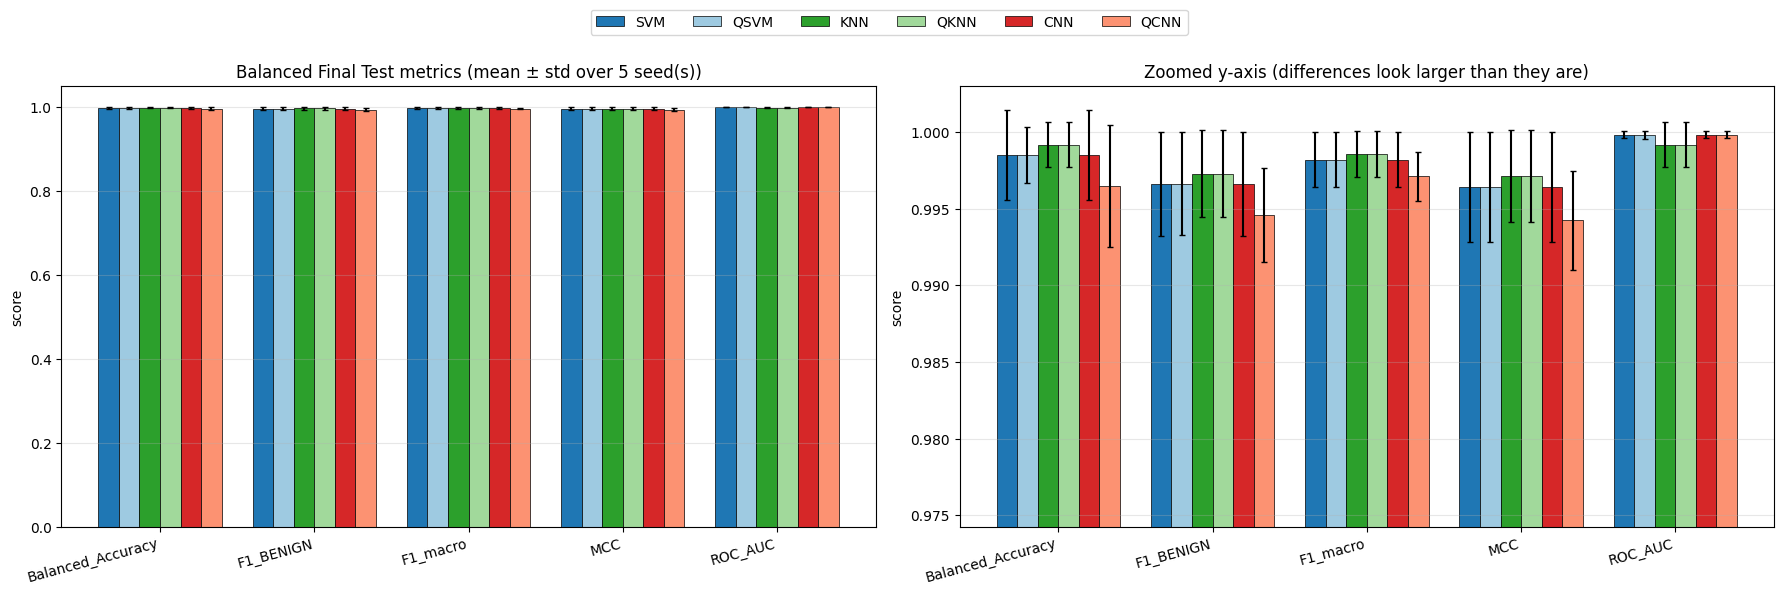

In [23]:
# 10.3  Bar chart للمقاييس المتوازنة (المتوسط ± std) — لوحة كاملة المدى + لوحة مكبّرة
METRICS_PLOT = ["Balanced_Accuracy", "F1_BENIGN", "F1_macro", "MCC", "ROC_AUC"]
COLORS = {"SVM": "#1f77b4", "QSVM": "#9ecae1", "KNN": "#2ca02c", "QKNN": "#a1d99b", "CNN": "#d62728", "QCNN": "#fc9272"}

fig, axes = plt.subplots(1, 2, figsize=(18, 5.8))
width = 0.8 / len(MODEL_ORDER)
for ax, zoom in zip(axes, [False, True]):
    for i, mname in enumerate(MODEL_ORDER):
        vals = agg_mean.loc[mname, METRICS_PLOT].to_numpy(dtype=float)
        errs = np.nan_to_num(agg_std.loc[mname, METRICS_PLOT].to_numpy(dtype=float))
        ax.bar(np.arange(len(METRICS_PLOT)) + (i - (len(MODEL_ORDER) - 1) / 2) * width, vals, width, yerr=errs,
               capsize=2, label=mname, color=COLORS[mname], edgecolor="black", linewidth=0.5)
    ax.set_xticks(np.arange(len(METRICS_PLOT))); ax.set_xticklabels(METRICS_PLOT, rotation=15, ha="right")
    ax.grid(axis="y", alpha=0.3)
    if zoom:
        lo = np.nanmin(agg_mean[METRICS_PLOT].to_numpy(dtype=float)) - 0.02
        ax.set_ylim(max(0.0, lo), 1.003)
        ax.set_title("Zoomed y-axis (differences look larger than they are)")
    else:
        ax.set_ylim(0, 1.05); ax.set_title(f"Balanced Final Test metrics (mean ± std over {len(SEEDS)} seed(s))")
    ax.set_ylabel("score")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(MODEL_ORDER), bbox_to_anchor=(0.5, 1.03))
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(os.path.join(OUTPUT_DIR, "bar_balanced_metrics.png"), dpi=150, bbox_inches="tight")
plt.show()


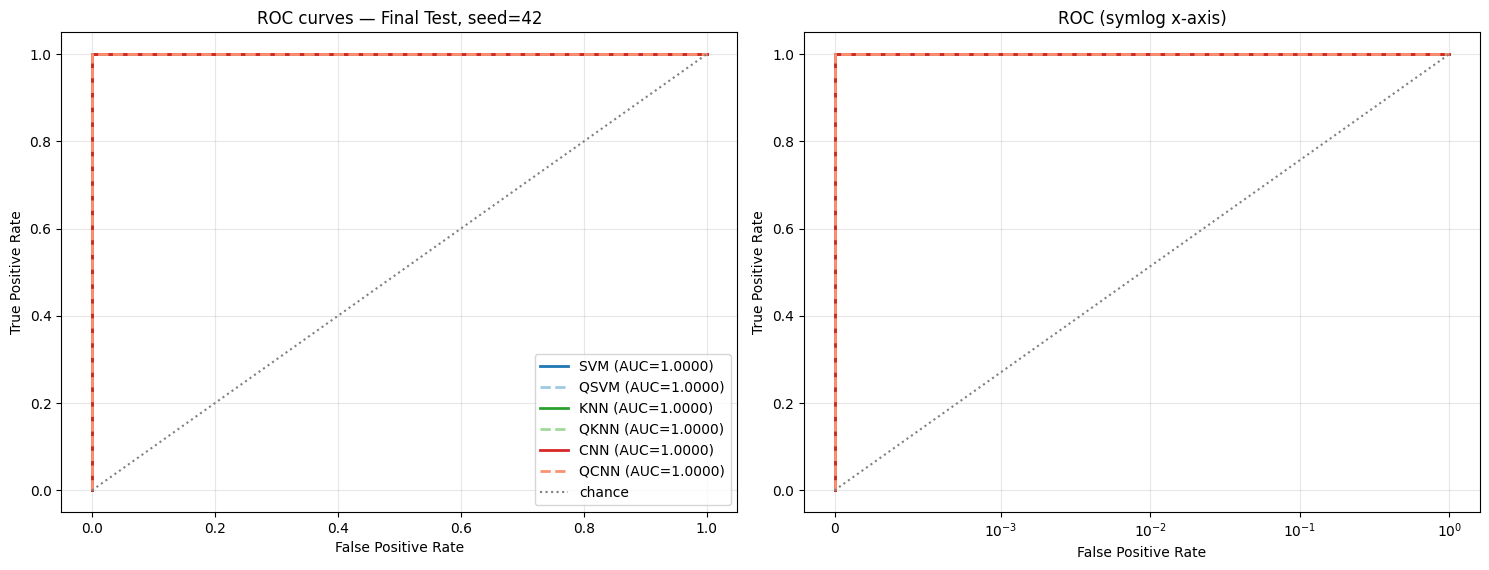

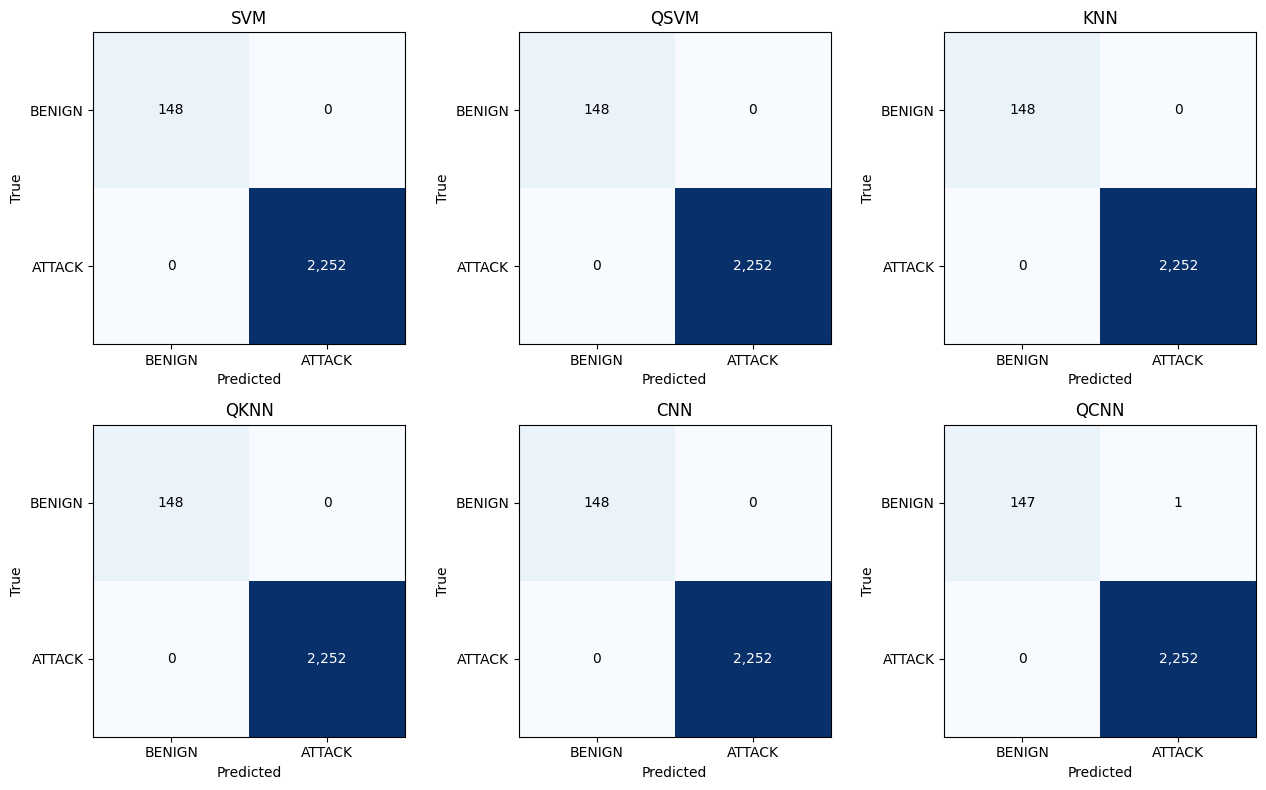

In [24]:
# 10.4  منحنيات ROC (الـ seed الأساسي) — مقياس خطي ومقياس لوغاريتمي لمحور FPR
det = STATE["eval_details"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for ax, logx in zip(axes, [False, True]):
    for mname in MODEL_ORDER:
        auc_v = fair_primary.set_index("Model").loc[mname, "ROC_AUC"]
        ls = "--" if mname.startswith("Q") else "-"
        ax.plot(det[mname]["fpr"], det[mname]["tpr"], ls, color=COLORS[mname], lw=2, label=f"{mname} (AUC={auc_v:.4f})")
    ax.plot([0, 1], [0, 1], ":", color="gray", label="chance")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate"); ax.grid(alpha=0.3)
    if logx:
        ax.set_xscale("symlog", linthresh=1e-3); ax.set_title("ROC (symlog x-axis)")
    else:
        ax.set_title(f"ROC curves — Final Test, seed={SEEDS[0]}")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "roc_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

# مصفوفات الالتباس (الـ seed الأساسي)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, mname in zip(axes.ravel(), MODEL_ORDER):
    cm = det[mname]["cm"]
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["BENIGN", "ATTACK"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["BENIGN", "ATTACK"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(mname)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrices.png"), dpi=150, bbox_inches="tight")
plt.show()

In [25]:
# 10.5  مقارنة الأزواج تقليدي ↔ كمومي (فروق مقترنة عبر الـ seeds: نفس العينة ونفس التقسيم لكل seed)
def pairwise_report(all_results, metric="F1_macro", practical_delta=0.005):
    seeds = sorted(all_results)
    print(f"فروق {metric} على Final Test (كمومي − تقليدي)، عدد الـ seeds = {len(seeds)}\n")
    for c, q in PAIRS:
        diffs = np.array([all_results[s].set_index("Model").loc[q, metric] - all_results[s].set_index("Model").loc[c, metric]
                          for s in seeds], dtype=float)
        mean = float(np.nanmean(diffs))
        sd = float(np.nanstd(diffs, ddof=1)) if len(diffs) > 1 else float("nan")
        wins, losses, ties = int(np.sum(diffs > 0)), int(np.sum(diffs < 0)), int(np.sum(diffs == 0))
        if len(seeds) < MIN_SEEDS_FOR_STRONG_CLAIM or np.isnan(sd):
            verdict = f"عدد الـ seeds أقل من {MIN_SEEDS_FOR_STRONG_CLAIM}: لا يمكن الحكم القوي."
        elif abs(mean) < practical_delta:
            verdict = f"الفرق أصغر من حد الأهمية العملي ({practical_delta}) → لا فرق عملي واضح."
        elif abs(mean) <= sd:
            verdict = "الفرق ضمن التباين بين الـ seeds → لا يوجد دليل ثابت على فرق حقيقي."
        elif mean > 0 and wins > losses:
            verdict = f"{q} أعلى في هذا الإعداد، لكن الاستنتاج محصور بهذه البيانات والمحاكاة."
        elif mean < 0 and losses > wins:
            verdict = f"{c} أعلى في هذا الإعداد، لكن الاستنتاج محصور بهذه البيانات والمحاكاة."
        else:
            verdict = "المتوسط لا يتفق مع اتجاه الفوز عبر الـ seeds؛ لا تستنتج تفوقًا."
        sd_txt = "n/a" if np.isnan(sd) else f"{sd:.4f}"
        print(f"{q:5s} − {c:4s}: {mean:+.4f} ± {sd_txt} | {q} أعلى في {wins} seed و {c} أعلى في {losses} و ties={ties}\n    → {verdict}")

for metric in ["F1_macro", "Balanced_Accuracy", "MCC", "ROC_AUC"]:
    pairwise_report(ALL_RESULTS, metric)
    print()


فروق F1_macro على Final Test (كمومي − تقليدي)، عدد الـ seeds = 5

QSVM  − SVM : +0.0000 ± 0.0013 | QSVM أعلى في 1 seed و SVM أعلى في 1 و ties=3
    → الفرق أصغر من حد الأهمية العملي (0.005) → لا فرق عملي واضح.
QKNN  − KNN : +0.0000 ± 0.0000 | QKNN أعلى في 0 seed و KNN أعلى في 0 و ties=5
    → الفرق أصغر من حد الأهمية العملي (0.005) → لا فرق عملي واضح.
QCNN  − CNN : -0.0011 ± 0.0010 | QCNN أعلى في 0 seed و CNN أعلى في 3 و ties=2
    → الفرق أصغر من حد الأهمية العملي (0.005) → لا فرق عملي واضح.

فروق Balanced_Accuracy على Final Test (كمومي − تقليدي)، عدد الـ seeds = 5

QSVM  − SVM : -0.0000 ± 0.0024 | QSVM أعلى في 1 seed و SVM أعلى في 1 و ties=3
    → الفرق أصغر من حد الأهمية العملي (0.005) → لا فرق عملي واضح.
QKNN  − KNN : +0.0000 ± 0.0000 | QKNN أعلى في 0 seed و KNN أعلى في 0 و ties=5
    → الفرق أصغر من حد الأهمية العملي (0.005) → لا فرق عملي واضح.
QCNN  − CNN : -0.0020 ± 0.0019 | QCNN أعلى في 0 seed و CNN أعلى في 3 و ties=2
    → الفرق أصغر من حد الأهمية العملي (0.005) → لا فرق عملي 

In [26]:
# 10.6  حفظ المخرجات
results_primary.to_csv(os.path.join(OUTPUT_DIR, "results_primary_seed.csv"), index=False)
pd.concat([r.assign(Seed=s) for s, r in ALL_RESULTS.items()]).to_csv(os.path.join(OUTPUT_DIR, "results_all_seeds.csv"), index=False)
fmt_pm(agg_mean, agg_std).to_csv(os.path.join(OUTPUT_DIR, "aggregate_mean_std.csv"))
for name, log in STATE["logs"].items():
    log.to_csv(os.path.join(OUTPUT_DIR, f"tuning_log_{name}.csv"), index=False)
print("تم حفظ الجداول والرسوم في:", os.path.abspath(OUTPUT_DIR))

تم حفظ الجداول والرسوم في: /content/ddos_qml_outputs


### Discussion — كيف تقرأ النتائج

**المقارنة العادلة هنا تعني:** نفس العينة، نفس التقسيم، نفس الـ preprocessing، نفس ميزانية الضبط داخل كل زوج، ونفس Final Test. لذلك إذا ظهر فرق فهو ليس بسبب أن نموذجًا رأى بيانات أكثر من الآخر.

**لكن الاستنتاج القوي لا يعتمد على Accuracy وحدها.** في DDoS توجد فئة نادرة، لذلك المقاييس الحاسمة هي:
`Balanced_Accuracy`, `F1_BENIGN`, `F1_macro`, `MCC`, و `ROC_AUC`.
أما `Accuracy` و `F1` في الجدول فهما موجهان غالبًا للفئة الموجبة `ATTACK` وقد يكونان مضللين عند اختلال الفئات.

**متى تقول إن نموذجًا تفوّق؟**
1. أن يكون الفرق في `pairwise_report` موجبًا للنموذج الكمومي أو التقليدي عبر أكثر من مقياس متوازن.
2. أن يتجاوز الفرق الانحراف المعياري عبر الـ seeds وحد الأهمية العملي `practical_delta`.
3. أن يكون اتجاه الفوز متكررًا عبر أغلب الـ seeds، لا في seed واحد فقط.
4. أن يكون Validation و Final Test يحتويان عددًا كافيًا من الفئة النادرة؛ الخلية 5 تفحص ذلك تلقائيًا.

**قيود يجب ذكرها عند عرض النتائج:**
1. النماذج الكمومية هنا محاكاة بلا ضجيج على CPU، وليست تشغيلًا على عتاد كمومي حقيقي.
2. الأزمنة الكمومية هي أزمنة محاكاة، ولا تصلح كدليل مباشر على سرعة أو بطء العتاد الكمومي.
3. عدد الميزات محدود بـ PCA بسبب تكلفة المحاكاة؛ الاستنتاج خاص بهذا الإعداد.
4. اختيار feature map و QCNN ansatz و `ANGLE_SCALE=np.pi/2` خيارات تصميم؛ قد توجد دوائر أفضل.
5. `FULL_CLASSICAL_RUN`، إن فُعّل، مرجعي فقط لأنه يغيّر حجم بيانات التدريب ولا يدخل في المقارنة العادلة.

**لتقوية التقرير النهائي أكثر:** استخدم 10 seeds أو أكثر، وكرّر التجربة على أكثر من ملف/نوع هجوم من CIC-DDoS2019، واذكر دائمًا عدد عينات BENIGN في Train/Validation/Test.
